# AI-Based Dynamic Resource Allocation for B5G Network Slicing
### Prédire la QoS des slices avec un GNN et tester sa robustesse aux changements brusques du réseau

**Projet SMARTICT — INPT, filière Smart ICT**

Le contexte scientifique (network slicing, allocation WFQ, réseaux de neurones sur graphes, RouteNet) est présenté au **chapitre 1 du rapport** ; le **guide du code** (`Guide_du_code.pdf`) décrit chaque fichier. Les références citées ici entre parenthèses sont détaillées dans la dernière cellule.

Ce notebook suit la feuille de route du guide (L1 → L6) :

| Section | Livrable |
|---|---|
| 1. Exploration du dataset | L1 — EDA + description des variables |
| 2. Formulation du problème | L2 — cible, hypothèses, protocole |
| 3. Baselines | L3 — code, résultats, analyse |
| 4. Événements | L4 — méthode, visualisations, justification |
| 5. Graphe et GNN | L5 — graphe, architecture, résultats |
| 6. Comparaison et ablation | L6 — comparaison, discussion |
| 7. Analyse et limites | L6 — réponses aux questions du guide |

**Organisation du code.** Le code réutilisable est dans `code/` (chaque fichier est commenté) :

| Fichier | Rôle |
|---|---|
| `extraction.py` | lit les archives brutes du simulateur et produit 4 tables Parquet |
| `features.py` | features par flux, calculées uniquement à partir des entrées de simulation |
| `preparation.py` | classes de flux (dédoublonnage), masque d'événements, graphes |
| `splits.py` | découpages train/val/test par topologie |
| `run_tabular.py` | baseline naïve, Ridge, Gradient Boosting, MLP |
| `gnn.py`, `run_gnn.py` | GNN hétérogène flux / files WFQ / liens, entraînement |
| `evaluation.py` | MAE / MSE pondérées par flux |

Les étapes longues (extraction ≈ 6 min, préparation ≈ 3 min, un GNN ≈ 30 à 80 min sur CPU) sont mises en cache dans `data/processed/` et `results/`. Mettre `FORCE = True` pour tout recalculer.

In [1]:
# Imports, chemins et style des figures.
# FORCE = True : tout recalculer (extraction, préparation, entraînements) au lieu de relire le cache.
import os, sys, json, pickle, subprocess, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import networkx as nx

warnings.filterwarnings("ignore", category=FutureWarning)
ROOT = os.path.abspath(".")
sys.path.insert(0, os.path.join(ROOT, "code"))
from features import FEATURES, FEATURE_GROUPS, TARGETS, PROCESSED, load_raw, build_flow_table, deduplicate
from splits import make_splits, describe
from evaluation import load_meta, load_preds, metrics, evaluate, RESULTS
import run_tabular

FORCE = False
FIG = os.path.join(ROOT, "figures"); os.makedirs(FIG, exist_ok=True)
RAW = os.path.join(ROOT, "data", "raw", "2.2.1-10kprocessed")

# Style des figures : palette catégorielle de référence (validée daltonisme), encre neutre
SLICE_COL = {"eMBB": "#2a78d6", "URLLC": "#eb6834", "mMTC": "#1baf7a"}
EVENT_COL = {"normal": "#b5b4ae", "surcharge": "#eb6834", "délestage": "#6250d6"}
INK, MUTED, ACCENT, BASE = "#0b0b0b", "#52514e", "#2a78d6", "#a3a29c"
mpl.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "font.size": 10, "axes.titlesize": 11,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
                     "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
                     "legend.frameon": False, "savefig.bbox": "tight"})
def save(fig, name):
    fig.savefig(os.path.join(FIG, name + ".png")); plt.show()
def wq(x, w, q=0.5):
    # quantile pondéré : valeur sous laquelle se trouve la fraction q du poids total
    o = np.argsort(x); c = np.cumsum(w[o]); return x[o][np.searchsorted(c, q * c[-1])]
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)

---
## 1. Exploration du dataset (L1)

### 1.1 Fichiers et structure

Le dataset est celui de **Farreras, Paillissé, Fàbrega et Vilà, *Generation of a network slicing dataset: the foundations for AI-based B5G resource management*, Data in Brief 55 (2024)**, DOI [10.5281/zenodo.10610616](https://doi.org/10.5281/zenodo.10610616). Il a été produit avec un simulateur à événements discrets au niveau paquet (BNNetSimulator, OMNeT++) sur des topologies réelles de l'Internet Topology Zoo.

Chaque **échantillon = une simulation** en régime stationnaire d'un réseau de transport auquel on a ajouté des antennes et des slices (eMBB, URLLC, mMTC). Le fichier `slicing-simulations.zip` (271 Mo, MD5 vérifié) contient :

In [2]:
# Inventaire des fichiers bruts du dataset (nombre de fichiers par dossier).
arch = sorted(f for f in os.listdir(RAW) if f.endswith(".tar.gz"))
struct = pd.DataFrame([
    ("graphs/graph_n.txt", len(os.listdir(os.path.join(RAW, "graphs"))), "topologie GML : nœuds typés, files, poids WFQ, capacités"),
    ("routings/routing_n.txt", len(os.listdir(os.path.join(RAW, "routings"))), "matrice de routage (port de sortie par destination)"),
    ("slices/slices_n.json", len(os.listdir(os.path.join(RAW, "slices"))), "slices : type, delta, flux (origine, destination, chemin, débit)"),
    ("results_*.tar.gz", len(arch), "100 simulations chacune : simulationResults, traffic, linkUsage, stability, input_files"),
], columns=["fichier", "nombre", "contenu"])
struct

,fichier,nombre,contenu
0,graphs/graph_n.txt,7984,"topologie GML : nœuds typés, files, poids WFQ,..."
1,routings/routing_n.txt,7984,matrice de routage (port de sortie par destina...
2,slices/slices_n.json,7984,"slices : type, delta, flux (origine, destinati..."
3,results_*.tar.gz,79,"100 simulations chacune : simulationResults, t..."


In [3]:
# Exemple : début d'un fichier de slices (une slice eMBB et son premier flux)
with open(os.path.join(RAW, "slices", "slices_175.json")) as fh:
    ex = json.load(fh)
print(json.dumps({**ex[0], "flows": ex[0]["flows"][:1]}, indent=1))

{
 "flows": [
  {
   "origin_node": 21,
   "destination": 16,
   "origin_node_antenna": 12,
   "path": "[21, 12, 7, 16]",
   "bandwidth": 18000000,
   "traffic_string": "0,18000000,1500,10,2,6000,12000,18000"
  }
 ],
 "delta": 0.715,
 "type": "eMBB",
 "number": 0
}


Les archives contiennent des matrices N×N « à plat » (plusieurs Mo par ligne). Nous avons écrit notre propre parseur (`code/extraction.py`) à partir de la documentation du dataset (`features.pdf`). Le parseur fourni (`datanetAPI.py`) n'a servi que de référence de format : il décode les slices avec `jsonpickle`, qui peut exécuter du code, et nous ne l'avons pas exécuté.

Trois pièges de format ont été identifiés et vérifiés, car chacun fausse silencieusement toutes les features :
1. **les chemins** : le champ `path` des fichiers de slices ne correspond pas toujours au routage simulé. Le trafic suit le fichier `routings/routing_n.txt` (matrice nœud × destination → port de sortie). Nous reconstruisons donc chaque chemin à partir du routage (vérification plus bas : charge offerte et utilisation mesurée concordent) ;
2. **les poids WFQ** sont donnés par port de sortie (« ; » sépare les ports, « , » les files), alors que l'affectation ToS → file est donnée par nœud ;
3. **l'identifiant de simulation** de `input_files.txt` recommence à 0 dans chaque archive : l'identifiant global est le numéro du fichier `graph_n.txt`.

L'extraction produit quatre tables :

In [4]:
# Chargement des 4 tables produites par code/extraction.py et taille de chacune.
samples, flows_raw, links_raw, queues_raw = load_raw()
errors = pd.read_csv(os.path.join(PROCESSED, "extraction_errors.csv"))
pd.DataFrame({"table": ["samples", "flows", "links", "queues"],
              "lignes": [len(samples), len(flows_raw), len(links_raw), len(queues_raw)],
              "une ligne =": ["une simulation", "un flux (origine→destination)", "un lien orienté", "une file WFQ active d'un port d'antenne"]})

,table,lignes,une ligne =
0,samples,7127,une simulation
1,flows,1576669,un flux (origine→destination)
2,links,3538248,un lien orienté
3,queues,263287,une file WFQ active d'un port d'antenne


In [5]:
# Chiffres clés : simulations conservées / écartées, topologies, tailles, types de nœuds.
print(f"Simulations : {len(samples)} conservées, {len(errors)} écartées (statut ≠ OK : régime stationnaire non atteint)")
print(f"Topologies distinctes : {samples.topology.nunique()}  |  simulations par topologie : "
      f"médiane {samples.groupby('topology').size().median():.0f}, min {samples.groupby('topology').size().min()}, max {samples.groupby('topology').size().max()}")
print(f"Taille des réseaux : {samples.n_nodes.min()} à {samples.n_nodes.max()} nœuds (médiane {samples.n_nodes.median():.0f})")
print("Types de nœuds (une simulation) :")
G0 = nx.read_gml(os.path.join(RAW, "graphs", "graph_175.txt"), destringizer=int)
print(pd.Series([G0.nodes[n]["type"] for n in G0]).value_counts().to_string())
samples.head()

Simulations : 7127 conservées, 773 écartées (statut ≠ OK : régime stationnaire non atteint)
Topologies distinctes : 162  |  simulations par topologie : médiane 41, min 1, max 114
Taille des réseaux : 16 à 765 nœuds (médiane 181)
Types de nœuds (une simulation) :
origin_mmtc          198
origin_urllc          29
origin_embb            8
inner                  6
antenna                5
destination_embb       2
destination_urllc      2
destination_mmtc       2


,sim,line,topology,n_nodes,n_links,n_flows,n_slices,n_antennas,global_packets,global_losses,global_delay,max_avg_lambda,sim_time,stability
0,100,0,Goodnet,101,230,81,27,4,206161.0,11151.7,0.003020,18000000.0,6225.0,0.000869
1,101,1,Epoch,72,146,63,9,3,138981.0,75977.6,0.002025,18000000.0,26500.0,0.000985
2,102,2,Ernet,167,338,134,34,2,376449.0,133134.0,0.003914,18000000.0,5550.0,0.000930
3,103,3,Grena,105,208,86,15,4,212237.0,21024.6,0.003699,18000000.0,5825.0,0.000885
4,104,4,Bandcon,137,286,112,17,2,305563.0,162990.0,0.003757,18000000.0,15900.0,0.000989


**Structure d'un réseau simulé.** Les nœuds `origin_*` sont les terminaux d'un type de slice. Chacun envoie un flux vers un nœud `destination_*` en passant par une **antenne**, puis par des nœuds de **transport** (`inner`). À l'antenne, chaque port de sortie applique un ordonnancement **WFQ** avec **une file par slice** : le poids de la file est la part de capacité réservée à la slice. C'est le levier de gestion des ressources. Le transport est FIFO (une seule file). Les réservations suivent la formule de l'article : $V_{res} = V_{min} + \delta\,(V_{max}-V_{min})$, avec $V_{min}=90\,\%$ et $V_{max}=120\,\%$ du débit nominal de la slice, et $\delta\in[0,1]$.

### 1.2 Dictionnaire des variables

Livrable demandé : *variable → signification → type → rôle potentiel → justification*. Les rôles : **demande** (ce que les slices injectent), **ressource** (ce que l'opérateur alloue ou ce dont le réseau dispose), **QoS** (ce qui est mesuré en sortie, donc cible et jamais feature), **contexte** (structure).

In [6]:
# Livrable L1 : dictionnaire « variable -> signification -> type -> rôle -> justification ».
# Rôles : demande (ce que la slice injecte), ressource (ce que l'opérateur alloue),
# QoS (sortie mesurée : cible, jamais feature), contexte, qualité.
var = pd.DataFrame([
 ("slice_type", "type de slice du flux (eMBB, URLLC, mMTC)", "catégorielle", "demande", "fixe débit, taille de paquet et exigences (SLA)"),
 ("delta", "paramètre δ de réservation de la slice", "réel [0,1]", "ressource", "levier de l'opérateur : fixe la réservation entre 90 % et 120 % du nominal"),
 ("bandwidth (demand_bw)", "débit nominal déclaré du flux", "réel (bit/s)", "demande", "18 Mb/s eMBB, 3,5 Mb/s URLLC, 0,2 Mb/s mMTC"),
 ("avg_pkts_lambda", "paquets générés par seconde (Poisson)", "réel", "demande", "intensité réelle du trafic"),
 ("pkt_size", "taille moyenne réelle des paquets (binomiale)", "réel (bits)", "demande", "corrigée : le champ « AvgPktSize » est incohérent pour eMBB/mMTC"),
 ("offered", "débit offert réel = λ × taille", "réel (bit/s)", "demande", "1,25 × nominal pour eMBB et mMTC ; égal au débit mesuré"),
 ("path / links", "chemin du flux (liste de nœuds / liens)", "liste d'entiers", "contexte", "définit les ressources partagées par le flux"),
 ("wfq_weight", "poids WFQ (%) de la file du flux au port de l'antenne", "réel", "ressource", "part de capacité réservée à la slice"),
 ("capacity", "capacité d'un lien", "réel (bit/s)", "ressource", "25 à 400 Mb/s"),
 ("schedulingPolicy / levelsQoS", "ordonnancement et nombre de files d'un nœud", "catégorielle / entier", "ressource", "WFQ multi-files aux antennes, FIFO ailleurs"),
 ("queueSizes", "taille des files (paquets)", "entier", "ressource", "constante = 32 : non informative"),
 ("n_nodes, n_antennas, n_flows", "taille du réseau simulé", "entier", "contexte", "16 à 765 nœuds ; teste la généralisation"),
 ("delay (AvgDelay)", "délai moyen par paquet du flux", "réel (s)", "QoS → cible", "de 10 µs à > 100 s : modélisé en log10"),
 ("p10…p90, jitter", "percentiles et variance du délai", "réels", "QoS", "très corrélés au délai moyen (non utilisés)"),
 ("pkts_drop / pkts_gen", "taux de pertes du flux", "réel [0,1]", "QoS → cible", "seconde cible"),
 ("meas_util, meas_loss (liens, files)", "utilisation et pertes mesurées", "réels [0,1]", "QoS (sortie)", "mesures de sortie : interdites comme features (fuite)"),
 ("global_delay / losses / packets", "agrégats réseau mesurés", "réels", "QoS (sortie)", "analyse uniquement"),
 ("sim_time, stability", "durée et critère de stabilité de la simulation", "réels", "qualité", "simulations non stables déjà écartées"),
], columns=["variable", "signification", "type", "rôle potentiel", "justification"])
var.to_csv(os.path.join(RESULTS, "dictionnaire_variables.csv"), index=False)
var

,variable,signification,type,rôle potentiel,justification
0,slice_type,"type de slice du flux (eMBB, URLLC, mMTC)",catégorielle,demande,"fixe débit, taille de paquet et exigences (SLA)"
1,delta,paramètre δ de réservation de la slice,"réel [0,1]",ressource,levier de l'opérateur : fixe la réservation en...
2,bandwidth (demand_bw),débit nominal déclaré du flux,réel (bit/s),demande,"18 Mb/s eMBB, 3,5 Mb/s URLLC, 0,2 Mb/s mMTC"
3,avg_pkts_lambda,paquets générés par seconde (Poisson),réel,demande,intensité réelle du trafic
4,pkt_size,taille moyenne réelle des paquets (binomiale),réel (bits),demande,corrigée : le champ « AvgPktSize » est incohér...
5,offered,débit offert réel = λ × taille,réel (bit/s),demande,"1,25 × nominal pour eMBB et mMTC ; égal au déb..."
6,path / links,chemin du flux (liste de nœuds / liens),liste d'entiers,contexte,définit les ressources partagées par le flux
7,wfq_weight,poids WFQ (%) de la file du flux au port de l'...,réel,ressource,part de capacité réservée à la slice
8,capacity,capacité d'un lien,réel (bit/s),ressource,25 à 400 Mb/s
9,schedulingPolicy / levelsQoS,ordonnancement et nombre de files d'un nœud,catégorielle / entier,ressource,"WFQ multi-files aux antennes, FIFO ailleurs"


### 1.3 Types, valeurs manquantes, doublons, anomalies

In [7]:
# Qualité des données : types, valeurs manquantes, délais indéfinis, doublons exacts.
print(flows_raw.drop(columns=["path", "links"]).dtypes.value_counts().to_string(), "\n")
print("Valeurs manquantes par table :", {k: int(v.isna().sum().sum()) for k, v in
      {"samples": samples, "flows": flows_raw, "links": links_raw, "queues": queues_raw}.items()})
print("Manquants dans links :", links_raw.isna().sum()[lambda x: x > 0].to_dict(),
      "-> taille de paquet mesurée indéfinie (« -nan ») sur les liens sans trafic : sans objet, non utilisée")
print("Flux avec délai = -1 (100 % des paquets perdus) :", int((flows_raw.delay <= 0).sum()))
print("Doublons exacts (sim, origine, destination) :", int(flows_raw.duplicated(["sim", "src", "dst"]).sum()))

float64    16
int64       8
object      1
bool        1 



Valeurs manquantes par table : {'samples': 0, 'flows': 0, 'links': 1854824, 'queues': 0}


Manquants dans links : {'meas_pkt_size': 1854824} -> taille de paquet mesurée indéfinie (« -nan ») sur les liens sans trafic : sans objet, non utilisée
Flux avec délai = -1 (100 % des paquets perdus) : 9
Doublons exacts (sim, origine, destination) : 0


**Quasi-doublons.** Il n'y a pas de doublon exact, mais beaucoup de flux ont des **entrées identiques** : même slice, même antenne, même file WFQ et même chemin après l'antenne. Ils ne diffèrent que par leur terminal d'origine, relié à l'antenne par un lien d'accès dédié très peu chargé. Leur QoS mesurée est quasi identique. Nous les regroupons en **classes de flux** avec un poids $w$ (nombre de flux de la classe). Une classe correspond exactement à une file WFQ active : « une slice à une antenne ». Toutes les pertes d'apprentissage et toutes les métriques sont pondérées par $w$, donc exactement équivalentes à un calcul flux par flux, pour un coût divisé par 6.

In [8]:
# Classes de flux : regroupement des flux aux entrées identiques (code/features.deduplicate).
# Si le cache n'existe pas, on lance code/preparation.py (≈ 3 min).
if FORCE or not os.path.exists(os.path.join(PROCESSED, "flow_classes.parquet")):
    subprocess.run([sys.executable, os.path.join("code", "preparation.py")], check=True)
ft = pd.read_parquet(os.path.join(PROCESSED, "flow_classes.parquet"))
print(f"{int(ft.w.sum())} flux -> {len(ft)} classes (multiplicité moyenne {ft.w.mean():.2f}, max {ft.w.max()})")
print(f"Part des flux qui ont au moins un jumeau : {1 - (ft.w == 1).sum() / ft.w.sum():.1%}")
print(f"Écart-type intra-classe de log10(délai) : moyenne {np.average(ft.y_delay_std, weights=ft.w):.1e} décade")

1576669 flux -> 263287 classes (multiplicité moyenne 5.99, max 695)
Part des flux qui ont au moins un jumeau : 93.4%
Écart-type intra-classe de log10(délai) : moyenne 9.7e-03 décade


In [9]:
# Tableau des anomalies détectées dans le dataset, avec leur ampleur et leur traitement.
q = pd.read_parquet(os.path.join(PROCESSED, "queues_feat.parquet"))
anom = pd.DataFrame([
 ("Chemins des slices", "le champ path des fichiers de slices diffère du routage réellement simulé",
  f"{1 - flows_raw.slice_path_ok.mean():.0%} des flux, {(~flows_raw.groupby('sim').slice_path_ok.all()).mean():.0%} des simulations", "chemins reconstruits depuis le fichier de routage"),
 ("Réservation hors chemin", "le flux traverse un port d'antenne où sa slice n'a aucune réservation (poids WFQ ≈ 0,001 %) : réservation placée selon le champ path, trafic routé autrement",
  f"{np.average(ft.wfq_weight <= 0.002, weights=ft.w):.1%} des flux (file quasi affamée)", "conservé : effet réel, à l'origine de la majorité des surcharges"),
 ("Taille de paquet", "le champ AvgPktSize vaut 6000 bits pour eMBB alors que les deux tailles tirées valent 12000/18000",
  f"débit mesuré eMBB médian {flows_raw[flows_raw.slice_type=='eMBB'].meas_bw_kbps.median()/1e3:.1f} Mb/s pour 18 Mb/s nominaux", "taille réelle = moyenne des deux tailles"),
 ("Poids WFQ négatifs", "quelques poids légèrement négatifs (résidus d'arrondi, ≥ -0,03 %)", "rares", "ramenés à 0"),
 ("Slices sous-dimensionnées", "réservation calculée sur le débit nominal, alors que le débit réel est 1,25 × nominal",
  f"{(ft.rho_q.repeat(ft.w) > 1).mean():.0%} des flux ont débit offert > débit réservé", "phénomène réel du dataset, conservé"),
 ("Surcharge du transport", "beaucoup de liens ont une charge offerte > capacité",
  f"{(ft.rho_path_max.repeat(ft.w) > 1).mean():.0%} des flux traversent un lien surchargé", "conservé : il crée les régimes de saturation"),
 ("Délais extrêmes", "files WFQ quasi affamées (poids ≈ 0,05 %)", f"délai max {flows_raw.delay.max():.0f} s", "cible en log10"),
 ("Délai = -1", "flux dont tous les paquets sont perdus", f"{int((flows_raw.delay <= 0).sum())} flux", "exclus de la cible délai"),
], columns=["anomalie", "description", "ampleur", "traitement"])
anom

,anomalie,description,ampleur,traitement
0,Chemins des slices,le champ path des fichiers de slices diffère d...,"42% des flux, 76% des simulations",chemins reconstruits depuis le fichier de routage
1,Réservation hors chemin,le flux traverse un port d'antenne où sa slice...,8.1% des flux (file quasi affamée),"conservé : effet réel, à l'origine de la major..."
2,Taille de paquet,le champ AvgPktSize vaut 6000 bits pour eMBB a...,débit mesuré eMBB médian 22.5 Mb/s pour 18 Mb/...,taille réelle = moyenne des deux tailles
3,Poids WFQ négatifs,quelques poids légèrement négatifs (résidus d'...,rares,ramenés à 0
4,Slices sous-dimensionnées,"réservation calculée sur le débit nominal, alo...",91% des flux ont débit offert > débit réservé,"phénomène réel du dataset, conservé"
5,Surcharge du transport,beaucoup de liens ont une charge offerte > cap...,51% des flux traversent un lien surchargé,conservé : il crée les régimes de saturation
6,Délais extrêmes,"files WFQ quasi affamées (poids ≈ 0,05 %)",délai max 1929 s,cible en log10
7,Délai = -1,flux dont tous les paquets sont perdus,9 flux,exclus de la cible délai


In [10]:
# Vérification de l'extraction : la charge offerte calculée (entrées + routage) doit expliquer
# l'utilisation mesurée des liens (sortie du simulateur) tant que le lien n'est pas saturé.
lf = pd.read_parquet(os.path.join(PROCESSED, "links_feat.parquet"), columns=["rho", "meas_util", "off"])
u = lf[(lf.off > 0) & lf.meas_util.notna()]
print(f"corrélation min(ρ offert, 1) / utilisation mesurée : {np.corrcoef(u.rho.clip(upper=1), u.meas_util)[0, 1]:.3f} sur {len(u)} liens")
qq = pd.read_parquet(os.path.join(PROCESSED, "queues_feat.parquet"), columns=["meas_util", "offered"])
print(f"files WFQ avec trafic mais débit mesuré nul : {(qq.meas_util == 0).mean():.2%}")

corrélation min(ρ offert, 1) / utilisation mesurée : 0.984 sur 1683424 liens
files WFQ avec trafic mais débit mesuré nul : 0.00%


### 1.4 Distributions et relations

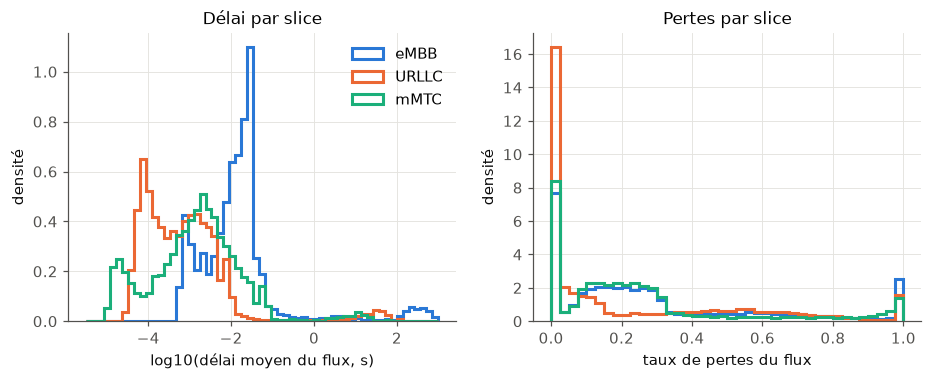

             delay  y_delay  y_loss
slice_type                         
URLLC       0.0005  -3.2823  0.0726
eMBB        0.0137  -1.8645  0.2130
mMTC        0.0016  -2.8106  0.1907


In [11]:
# Distribution des deux cibles par type de slice.
# fw = vue « un flux = une ligne » : chaque classe est répétée w fois, pour que les
# histogrammes et médianes soient calculés par flux et non par classe.
FW_COLS = ["sim", "slice_type", "delay", "y_delay", "y_loss", "delta", "wfq_weight", "rho_q", "rho_q_eff",
           "rho_path_max", "b", "log_b", "z", "event", "event_type"] + [c for c in FEATURES if c not in ("delta", "wfq_weight", "rho_q", "rho_q_eff", "rho_path_max")]
fw = ft.loc[ft.index.repeat(ft.w), FW_COLS].reset_index(drop=True)  # vue « un flux = une ligne »
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
bins = np.linspace(-5.5, 3, 60)
for s, c in SLICE_COL.items():
    d = fw[fw.slice_type == s]
    ax[0].hist(d.y_delay.dropna(), bins=bins, histtype="step", lw=2, color=c, density=True, label=s)
    ax[1].hist(d.y_loss, bins=np.linspace(0, 1, 41), histtype="step", lw=2, color=c, density=True, label=s)
ax[0].set(xlabel="log10(délai moyen du flux, s)", ylabel="densité", title="Délai par slice")
ax[1].set(xlabel="taux de pertes du flux", ylabel="densité", title="Pertes par slice")
ax[0].legend(); save(fig, "fig_targets")
print(fw.groupby("slice_type")[["delay", "y_delay", "y_loss"]].median().round(4))

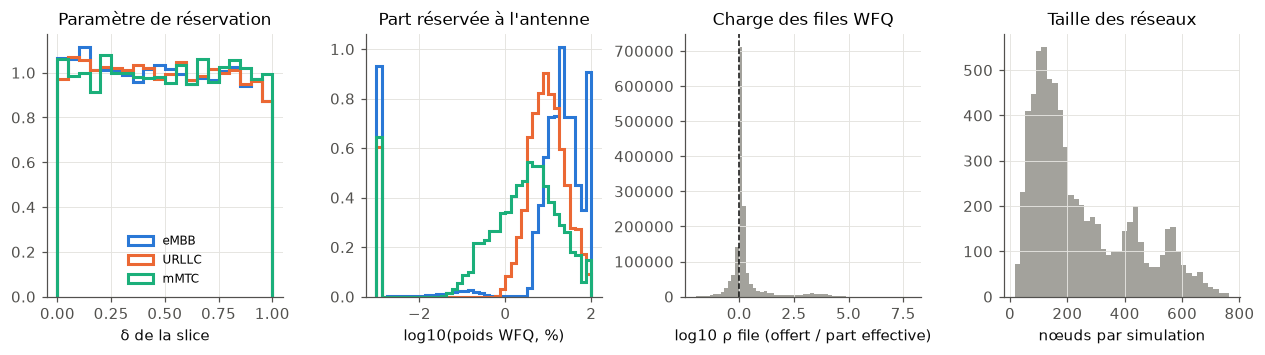

In [12]:
# Distribution des principales entrées : δ, poids WFQ, charge des files, taille des réseaux.
fig, ax = plt.subplots(1, 4, figsize=(14, 3.1), gridspec_kw={"wspace": .35})
for s, c in SLICE_COL.items():
    d = fw[fw.slice_type == s]
    ax[0].hist(d.delta, bins=20, histtype="step", lw=2, color=c, density=True, label=s)
    ax[1].hist(np.log10(d.wfq_weight.clip(lower=1e-3)), bins=40, histtype="step", lw=2, color=c, density=True)
ax[0].set(xlabel="δ de la slice", title="Paramètre de réservation"); ax[0].legend(fontsize=8)
ax[1].set(xlabel="log10(poids WFQ, %)", title="Part réservée à l'antenne")
ax[2].hist(np.log10(fw.rho_q_eff.clip(lower=1e-2)), bins=60, color=BASE); ax[2].axvline(0, color=INK, ls="--", lw=1)
ax[2].set(xlabel="log10 ρ file (offert / part effective)", title="Charge des files WFQ")
ax[3].hist(samples.n_nodes, bins=40, color=BASE); ax[3].set(xlabel="nœuds par simulation", title="Taille des réseaux")
save(fig, "fig_inputs")

**Où se trouve le changement de régime ?** Pour chaque flux, on définit la charge de son **goulot** :
$b = \max(\rho^{\text{file}}_{\text{eff}}, \max_{\ell \in \text{chemin}} \rho_\ell)$, c'est-à-dire le rapport débit offert / capacité de la ressource la plus chargée qu'il traverse (sa file WFQ à l'antenne ou un lien de transport). La figure montre la QoS médiane en fonction de $b$.

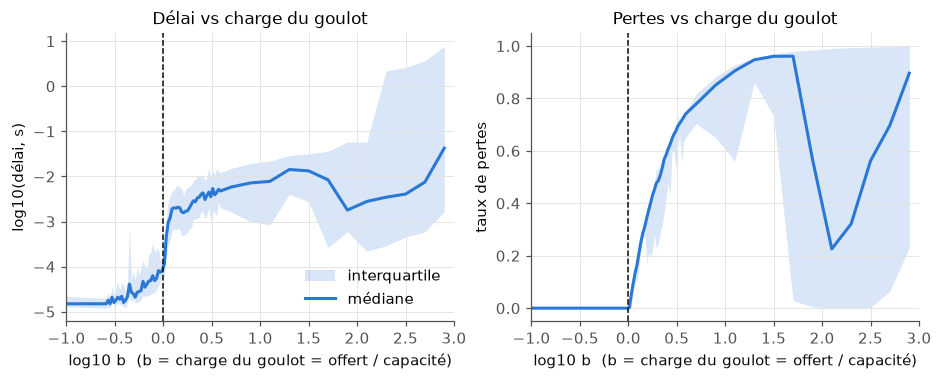

In [13]:
# QoS médiane (et interquartile) en fonction de la charge du goulot b, en échelle log.
# Bins fins autour de b = 1 (log10 b = 0) pour bien voir le coude de saturation.
cut = pd.cut(fw.log_b, np.r_[-1.5, np.arange(-0.6, 0.6, 0.02), np.arange(0.6, 3.01, 0.2)])
g = fw.groupby(cut, observed=True)
mid = np.array([i.mid for i in g.y_delay.median().index])   # centre de chaque intervalle de log10 b
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for a, col, lab in ((ax[0], "y_delay", "log10(délai, s)"), (ax[1], "y_loss", "taux de pertes")):
    a.fill_between(mid, g[col].quantile(.25), g[col].quantile(.75), color=ACCENT, alpha=.18, lw=0, label="interquartile")
    a.plot(mid, g[col].median(), color=ACCENT, lw=2, label="médiane")
    a.axvline(0, color=INK, ls="--", lw=1); a.set(xlabel="log10 b  (b = charge du goulot = offert / capacité)", ylabel=lab, xlim=(-1, 3))
ax[0].legend(); ax[0].set_title("Délai vs charge du goulot"); ax[1].set_title("Pertes vs charge du goulot")
save(fig, "fig_knee")

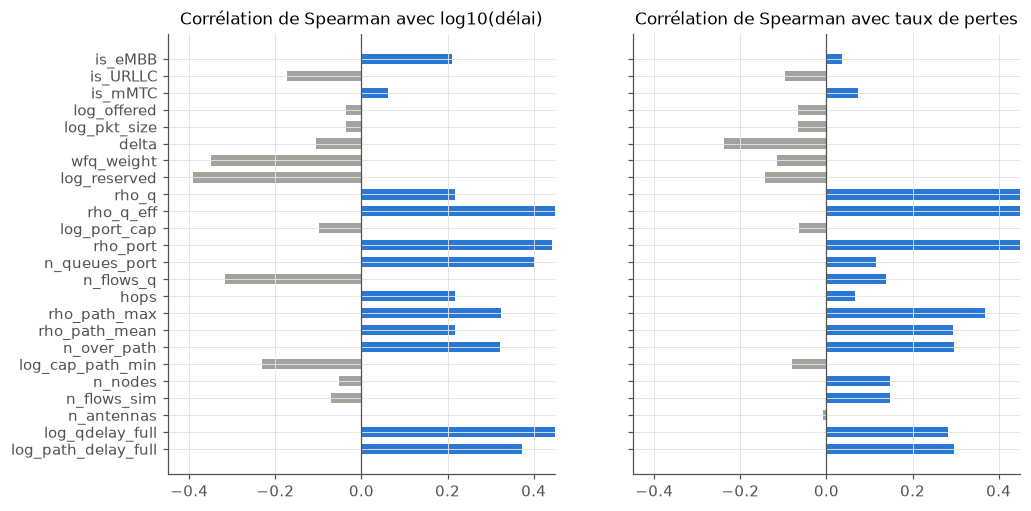

In [14]:
# Corrélation de Spearman (corrélation des rangs, robuste aux relations non linéaires
# monotones) entre chaque feature et chaque cible, sur 300 000 flux tirés au hasard.
corr = fw.sample(300_000, random_state=0)[FEATURES + TARGETS].corr(method="spearman")[TARGETS].drop(TARGETS)
fig, ax = plt.subplots(1, 2, figsize=(10, 5.2), sharey=True)
for a, t, ttl in ((ax[0], "y_delay", "log10(délai)"), (ax[1], "y_loss", "taux de pertes")):
    v = corr[t]; a.barh(v.index, v.values, color=[ACCENT if x > 0 else BASE for x in v.values], height=.6)
    a.axvline(0, color=MUTED, lw=.8); a.set(title=f"Corrélation de Spearman avec {ttl}", xlim=(-.45, .45))
ax[0].invert_yaxis(); save(fig, "fig_corr")

**Lecture de l'EDA.**
* Le délai couvre **8 ordres de grandeur** et sa distribution est **bimodale**. Un flux non congestionné a un délai de l'ordre de 10 µs à 0,1 ms (temps de transmission). Un flux congestionné est bloqué derrière une file de 32 paquets (ms à s). D'où la cible en log10.
* Les pertes sont fréquentes : médiane de 22 % (eMBB) et de 19 % (mMTC). Le dataset couvre surtout des régimes **saturés**. Cela découle de deux anomalies ci-dessus : le débit réel vaut 1,25 × le débit nominal sur lequel la réservation est calculée, et 8 % des flux passent par un port où leur slice n'a aucune réservation.
* La relation QoS / charge présente un **coude net en $b \approx 1$** (axe logarithmique, car $b$ couvre plus de dix ordres de grandeur). En dessous, il n'y a pas de pertes et le délai est faible ; au-dessus, les pertes croissent et le délai saute de deux décades. C'est ce changement de régime que nous utilisons pour définir les événements (section 4).
* Les meilleures features isolées sont le délai de file pleine pour le délai (|ρ| = 0,67) et la charge effective de la file WFQ pour les pertes (0,73). Aucune ne suffit : la QoS d'un flux dépend aussi des **autres flux** qui partagent ses ressources, et des pertes qu'ils subissent en amont, qui allègent les liens en aval. Cette dépendance relationnelle motive la représentation en graphe.

**Variables liées à la demande, aux ressources et à la QoS** (voir le dictionnaire) : demande = type de slice, débit offert, taille de paquet ; ressources = δ, poids WFQ, capacités, files ; QoS = délai, gigue, percentiles, pertes (sorties uniquement).

---
## 2. Formulation du problème (L2)

**Cible.** Pour chaque flux d'une slice, prédire sa QoS en régime établi, à partir de la configuration du réseau : topologie, routage, demandes de toutes les slices et réservations WFQ.
* $y_1 = \log_{10}(\text{délai moyen})$, cible principale (MAE en décades : 0,3 ≈ facteur 2). Le log est justifié par les 8 ordres de grandeur du délai, et parce que l'erreur absolue sur le log (log du rapport prédit / réel) pénalise symétriquement sur- et sous-estimation (Tofallis, 2015) ;
* $y_2 =$ taux de pertes $\in [0,1]$, cible secondaire.

**Pourquoi c'est un problème de gestion des slices.** L'opérateur choisit les réservations ($\delta$, donc les poids WFQ) et le placement des slices. Il doit vérifier, **avant** de déployer une configuration, que chaque slice respectera son contrat (SLA). Une simulation paquet coûte de quelques minutes à plusieurs heures (colonne `sim_time` : jusqu'à 15 h de calcul). Un modèle qui prédit la QoS par flux en quelques millisecondes sert de **jumeau numérique**. Il permet de comparer des allocations candidates (« et si je baisse δ de l'eMBB ? »), de contrôler l'admission d'une nouvelle slice et de détecter les slices qui violeront leur SLA. Prédire la QoS est donc l'étape d'évaluation d'une boucle d'allocation dynamique ; l'optimisation s'appuie ensuite sur ce modèle.

**Pourquoi pas une autre cible ?** Prédire directement « la bonne allocation » est impossible : le dataset ne contient pas d'allocation optimale étiquetée, seulement des allocations aléatoires et leurs conséquences. Prédire l'utilisation des liens est moins utile : un SLA porte sur le délai et les pertes d'une slice, pas sur un lien.

**Hypothèses testées.**
* **H1** : la QoS d'un flux dépend d'interactions entre flux (ressources partagées, pertes en amont). Un GNN qui modélise ces interactions doit faire mieux que des modèles à features par flux.
* **H2** : les erreurs sont plus grandes pendant les événements, c'est-à-dire quand la charge s'écarte du régime habituel du réseau.
* **H3** : les informations de réservation (δ, poids WFQ) et de charge sont nécessaires ; les retirer dégrade la prédiction.

**Protocole.**
* **Unité** : la classe de flux (poids $w$) ; métriques **MAE et MSE pondérées par flux**, sur les deux cibles.
* **Découpage par topologie** : environ 44 simulations par topologie. Une topologie présente à la fois en entraînement et en test permettrait de mémoriser sa structure. Train / validation / test contiennent donc des topologies **disjointes** (≈ 70/15/15 % des simulations) : c'est la validation par blocs recommandée pour les données groupées (Roberts et al., 2017).
* **Pas de fuite** : seules les **entrées** de la simulation sont des features. Utilisations et pertes mesurées sont exclues : elles ne sont connues qu'après la simulation, ce qui en ferait une fuite d'information (Kaufman et al., 2012). Normalisations et hyperparamètres sont appris ou choisis sur train et validation uniquement ; le test n'est lu qu'une fois.
* **Décalage de distribution** : second découpage où le test contient les **plus grands réseaux** (quart supérieur des tailles de topologie).

In [15]:
# Découpages train / val / test par topologie (code/splits.py) et leur description.
splits = make_splits(samples)
display(describe(splits, samples))
print("Seuil de taille du découpage 'shift' :", splits["shift_threshold"], "nœuds (médiane de la topologie)")

,split,part,simulations,topologies,noeuds_median
0,topo,train,5005,111,183.0
1,topo,val,1080,25,185.0
2,topo,test,1042,26,170.0
3,shift,train,4378,87,170.0
4,shift,val,935,22,161.0
5,shift,test,1814,53,244.5


Seuil de taille du découpage 'shift' : 212.0 nœuds (médiane de la topologie)


In [16]:
# Contexte opérationnel : SLA de l'article (Table 1) appliqués à la cible délai
SLA_DELAY = {"eMBB": 10e-3, "URLLC": 0.5e-3, "mMTC": 10.0}
sla = fw.groupby("slice_type").apply(lambda d: pd.Series({
    "SLA délai": SLA_DELAY[d.name], "flux": len(d),
    "violations du SLA délai": (d.delay > SLA_DELAY[d.name]).mean()}), include_groups=False)
sla

,SLA délai,flux,violations du SLA délai
slice_type,,,
URLLC,0.0005,325456.0,0.507098
eMBB,0.0100,66006.0,0.594491
mMTC,10.0000,1185207.0,0.012745


---
## 3. Baselines (L3)

| Modèle | Rôle | Entrées |
|---|---|---|
| **Naïf** | référence minimale : médiane (pondérée) de chaque cible par type de slice, apprise sur le train | type de slice |
| **Ridge** | modèle linéaire régularisé ; α choisi sur la validation | 24 features tabulaires standardisées |
| **Gradient Boosting** (HistGradientBoosting) | modèle ML non linéaire de référence ; taux d'apprentissage, feuilles et taille minimale choisis sur la validation (grille de 8) | 24 features |
| **MLP** | réseau dense 2×128, arrêt précoce sur la validation ; c'est le GNN sans graphe | 24 features |

Les 24 features sont calculées à partir des entrées uniquement, en 6 familles : *slice* (type, débit, taille de paquet), *réservation* (δ, poids WFQ, débit réservé, charges de file), *port d'antenne* (capacité, charge, nombre de files), *chemin* (nombre de sauts, charge max / moyenne des liens, nombre de liens surchargés, capacité min), *réseau* (taille) et *physique*.

La famille **physique** vient d'une observation : tous les flux d'une même file WFQ d'antenne ont la même QoS, alors que connaître seulement la simulation et la slice n'explique qu'environ la moitié de la variance (cellule suivante). La file WFQ est donc le bon niveau de modélisation. Quand une file de $B=32$ paquets est saturée, un paquet attend environ le temps de la vider : $B\cdot L / r$, avec $L$ la taille de paquet et $r$ le débit de service. D'où deux features issues d'un modèle fluide :
* `log_qdelay_full` $=\log_{10}\big(B\,L_{\text{slice}}/r_{\text{eff}}\big)$, où $r_{\text{eff}} = \frac{w_q}{\sum_{\text{actives}} w}\,C_{\text{port}}$ est le débit WFQ effectif de la file ;
* `log_path_delay_full` $=\log_{10}\big(\sum_{\ell:\ \rho_\ell>1} B\,\bar L_\ell / C_\ell\big)$ : le même délai, sommé sur les liens de transport surchargés du chemin.

Les features de chemin et de physique sont déjà des **résumés du graphe** construits à la main : la comparaison avec le GNN est donc exigeante.

In [17]:
# Les 6 familles de features (utilisées pour l'ablation).
pd.DataFrame([(k, ", ".join(v)) for k, v in FEATURE_GROUPS.items()], columns=["famille", "features"])

,famille,features
0,slice,"is_eMBB, is_URLLC, is_mMTC, log_offered, log_p..."
1,reservation,"delta, wfq_weight, log_reserved, rho_q, rho_q_eff"
2,antenna_port,"log_port_cap, rho_port, n_queues_port, n_flows_q"
3,path,"hops, rho_path_max, rho_path_mean, n_over_path..."
4,network,"n_nodes, n_flows_sim, n_antennas"
5,physique,"log_qdelay_full, log_path_delay_full"


In [18]:
# Part de variance expliquée en connaissant seulement le groupe (moyenne de la cible dans le groupe)
d = ft.dropna(subset=["y_delay"])
def r2_group(keys, col):
    m = d.groupby(keys)[col].transform("mean"); mu = np.average(d[col], weights=d.w)
    return 1 - np.average((d[col] - m) ** 2, weights=d.w) / np.average((d[col] - mu) ** 2, weights=d.w)
pd.DataFrame([(" + ".join(k), r2_group(k, "y_delay"), r2_group(k, "y_loss")) for k in
              (["sim"], ["sim", "slice_type"], ["sim", "antenna", "next_hop"], ["sim", "antenna", "next_hop", "wfq_queue"])],
             columns=["groupe connu", "R² log10 délai", "R² pertes"]).round(3)

,groupe connu,R² log10 délai,R² pertes
0,sim,0.158,0.297
1,sim + slice_type,0.489,0.559
2,sim + antenna + next_hop,0.556,0.654
3,sim + antenna + next_hop + wfq_queue,1.000,1.000


In [19]:
# Baselines (Livrable L3) : entraînement des 4 modèles sans graphe (ou lecture du cache),
# puis MAE / MSE du naïf et de Ridge, globalement et pendant les événements.
names = run_tabular.run("topo", None, ("naive", "ridge", "hgb", "mlp"), force=FORCE)
meta = load_meta()
LAB = {"naive": "Naïf", "ridge": "Ridge", "hgb": "Gradient Boosting", "mlp": "MLP", "gnn": "GNN"}
base = evaluate(["naive", "ridge"], meta, labels=LAB)
base[base.sous_ensemble.isin(["global", "événement"])].round(4)

,modèle,sous_ensemble,MAE_delay,MSE_delay,MAE_loss,MSE_loss,flux
0,Naïf,global,0.8255,1.2865,0.1965,0.0892,218628
2,Naïf,événement,1.7065,4.6116,0.4724,0.3138,29851
5,Ridge,global,0.5216,0.5327,0.1317,0.0387,218628
7,Ridge,événement,0.9694,1.5456,0.2555,0.1037,29851


**Lecture des baselines (test, topologies jamais vues).**
* Le modèle **naïf** se trompe en moyenne de 0,83 décade sur le délai (un facteur 7) et de 0,20 sur le taux de pertes. C'est le plancher à battre.
* **Ridge** divise l'erreur sur le délai par 1,6 (0,52 décade), mais une relation linéaire ne peut pas représenter le coude en $b pprox 1$ : l'erreur double pendant les événements (0,97).
* Les modèles non linéaires du chapitre 6 font beaucoup mieux : le Gradient Boosting atteint 0,28 décade.
* Pour tous les modèles, l'erreur est **2 à 2,5 fois plus grande pendant les événements**. C'est la question de robustesse posée par le guide (section 6).

---
## 4. Définition des événements (L4)

**Contrainte du dataset.** Les simulations sont des **régimes stationnaires indépendants**, sans axe temporel. On ne peut donc pas observer un réseau *avant* et *après* une rupture. En revanche, chaque topologie est simulée environ 44 fois avec des slices, des placements et des réservations différents : ces simulations décrivent le **régime habituel** de ce réseau. Un changement brusque (pic de trafic, ajout d'une slice, réduction de δ) place un flux dans un état **éloigné de ce régime habituel**. C'est cet écart que nous mesurons.

**Mesure de changement.** La variable d'état retenue est la charge du goulot $b$ (section 1.4). C'est elle qui pilote le changement de régime de la QoS, avec un coude juste au-dessus de $b=1$. Elle est calculée uniquement à partir des **entrées**, donc observable par l'opérateur avant la mesure de QoS. Comme $b$ couvre plus de dix ordres de grandeur (files WFQ quasi affamées), on mesure l'écart sur $\log_{10} b$ : un écart **multiplicatif** (« deux fois plus chargé que d'habitude »). Pour chaque flux :
$$z = \frac{\log_{10} b - \operatorname{médiane}_{\tau,s}(\log_{10} b)}{1{,}4826\cdot \operatorname{MAD}_{\tau,s}(\log_{10} b)}$$
où médiane et MAD (écart absolu médian) sont calculées sur tous les flux de la même topologie $\tau$ et du même type de slice $s$. Le facteur 1,4826 rend le MAD comparable à un écart-type ; un plancher de 0,02 décade évite les divisions par une dispersion quasi nulle.

**Règle.** Événement si $|z| \ge 3$ :
* **surcharge** ($z \ge 3$) : le goulot est beaucoup plus chargé que d'habitude (typiquement une slice dont la réservation est devenue très inférieure à sa demande) ;
* **délestage** ($z \le -3$) : le goulot est beaucoup moins chargé que d'habitude, souvent au point de **repasser sous la saturation**.

**Justification du seuil.** (i) $|z|\ge 3$ est l'**identificateur de Hampel** (Hampel, 1974 ; Leys et al., 2013), règle robuste standard de détection de valeurs aberrantes (≈ 0,3 % des valeurs pour une loi normale). Médiane et MAD résistent aux valeurs extrêmes, contrairement à la moyenne et à l'écart-type. Les queues de $\log_{10} b$ sont lourdes, d'où un seuil de 3 plutôt que 2 : à $|z|\ge2$, 19 % des flux seraient des « événements ». (ii) Le seuil isole environ 14 % des flux, assez pour une évaluation stable en test. (iii) Les événements coïncident avec un changement de régime de la QoS (tableau ci-dessous) : tous les flux en surcharge ont $b>1$, et presque tous les flux en délestage ont $b<1$.

Le masque sert **uniquement à l'évaluation** et n'est jamais une feature. Il utilise les simulations de la topologie testée, ce qui correspond à un opérateur qui connaît l'historique de son propre réseau.

In [20]:
# Répartition des flux par type d'événement et QoS médiane de chaque groupe :
# vérifie que les événements (définis sur les entrées) correspondent à des changements de régime.
tab = fw.groupby("event_type").agg(flux=("b", "size"), b_median=("b", "median"),
        part_b_sup_1=("b", lambda x: (x > 1).mean()), delai_log_median=("y_delay", "median"),
        pertes_median=("y_loss", "median"))
tab["part"] = tab.flux / tab.flux.sum()
tab.round(3)

,flux,b_median,part_b_sup_1,delai_log_median,pertes_median,part
event_type,,,,,,
délestage,46429,0.387,0.007,-4.602,0.000,0.029
normal,1362347,1.263,0.858,-2.915,0.166,0.864
surcharge,167893,148.320,1.000,-1.918,0.854,0.106


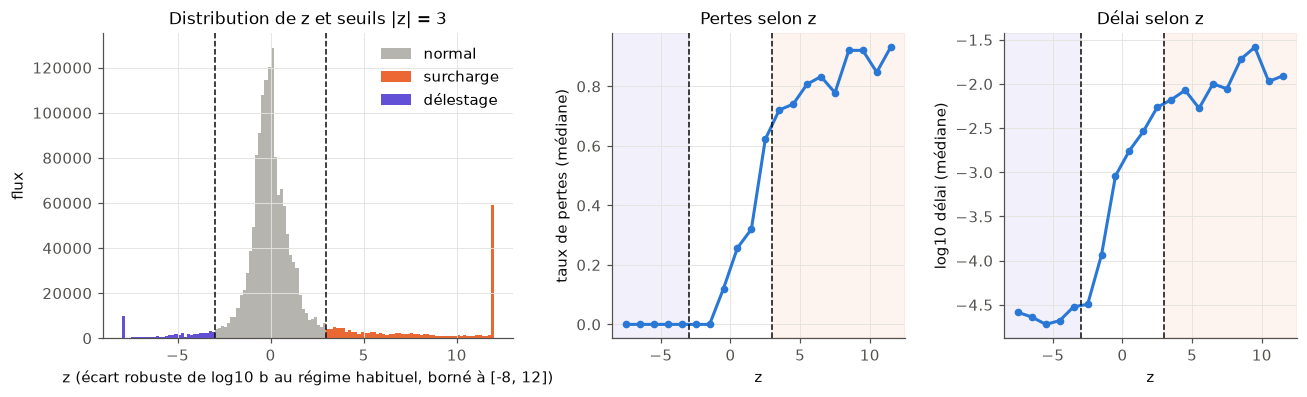

In [21]:
# Figure : distribution de z avec les seuils ±3, puis pertes et délai médians en fonction de z.
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6), gridspec_kw={"width_ratios": [1.4, 1, 1], "wspace": .3})
zb = np.clip(fw.z, -8, 12)
bins = np.linspace(-8, 12, 121)
for t, c in EVENT_COL.items():
    ax[0].hist(zb[fw.event_type == t], bins=bins, color=c, label=t)
for x in (-3, 3): ax[0].axvline(x, color=INK, ls="--", lw=1)
ax[0].set(xlabel="z (écart robuste de log10 b au régime habituel, borné à [-8, 12])", ylabel="flux", title="Distribution de z et seuils |z| = 3"); ax[0].legend()
g = fw.groupby(pd.cut(fw.z, np.arange(-8, 12.5, 1)), observed=True)
mid = [i.mid for i in g.y_delay.median().index]
for a, col, lab in ((ax[1], "y_loss", "taux de pertes (médiane)"), (ax[2], "y_delay", "log10 délai (médiane)")):
    a.plot(mid, g[col].median(), color=ACCENT, lw=2, marker="o", ms=4)
    a.axvspan(-8.5, -3, color=EVENT_COL["délestage"], alpha=.08); a.axvspan(3, 12.5, color=EVENT_COL["surcharge"], alpha=.08)
    for x in (-3, 3): a.axvline(x, color=INK, ls="--", lw=1)
    a.set(xlabel="z", ylabel=lab, xlim=(-8.5, 12.5))
ax[1].set_title("Pertes selon z"); ax[2].set_title("Délai selon z")
save(fig, "fig_events_z")

**Vérification visuelle.** On prend une topologie au cœur de transport riche et simulée de nombreuses fois. À gauche, chaque point est une classe de flux de l'une de ses simulations : les flux étiquetés sortent bien de la bande habituelle de $b$. Au centre et à droite, on vérifie que ces étiquettes, calculées uniquement à partir des entrées, correspondent à une QoS mesurée réellement différente.

Topologie Abvt : 48 simulations ; référence sim 4725, événement sim 5935 (78% des flux en surcharge)


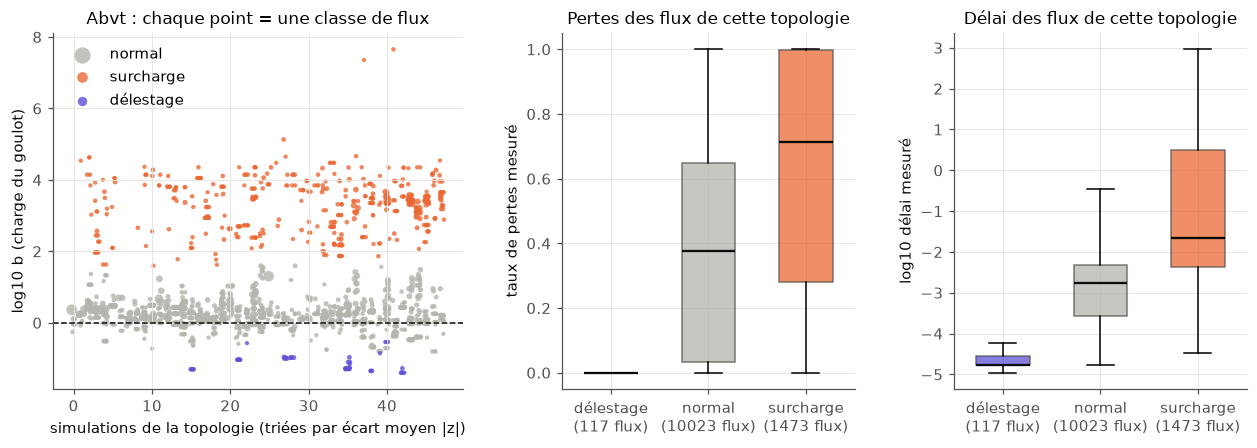

In [22]:
# Vérification visuelle sur une topologie : b de chaque classe de flux simulation par
# simulation, et QoS mesurée des flux normaux / en surcharge / en délestage.
links_f = pd.read_parquet(os.path.join(PROCESSED, "links_feat.parquet"))
core_size = (links_f[(links_f.src_type == "inner") & (links_f.dst_type == "inner")].groupby("sim").size()
             .rename("core").to_frame().join(samples.set_index("sim").topology).groupby("topology").core.median())
cnt = samples.topology.value_counts()
topo = core_size[(core_size.between(30, 90)) & (cnt.reindex(core_size.index) >= 40)].index[0]  # cœur lisible, beaucoup de simulations
sims_t = samples[samples.topology == topo].sim
# pour chaque simulation de la topologie : part de flux en surcharge et écart moyen |z|
per = ft[ft.sim.isin(sims_t)].groupby("sim").apply(lambda d: pd.Series({
    "surcharge": np.average(d.event_type == "surcharge", weights=d.w),
    "absz": np.average(d.z.abs(), weights=d.w)}), include_groups=False)
s_ref, s_evt = per.absz.idxmin(), per.surcharge.idxmax()
print(f"Topologie {topo} : {len(sims_t)} simulations ; référence sim {s_ref}, événement sim {s_evt} "
      f"({per.loc[s_evt, 'surcharge']:.0%} des flux en surcharge)")

fig, ax = plt.subplots(1, 3, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1.4, 1, 1], "wspace": .3})
order = per.sort_values("absz").index
d = ft[ft.sim.isin(sims_t)].copy(); d["x"] = d.sim.map({s: i for i, s in enumerate(order)})
for t, c in EVENT_COL.items():
    e = d[d.event_type == t]
    ax[0].scatter(e.x + np.random.default_rng(0).uniform(-.3, .3, len(e)), e.log_b, s=6 + 2 * np.sqrt(e.w), color=c, label=t, alpha=.8, lw=0)
ax[0].axhline(0, color=INK, ls="--", lw=1)
ax[0].set(xlabel="simulations de la topologie (triées par écart moyen |z|)", ylabel="log10 b (charge du goulot)", title=f"{topo} : chaque point = une classe de flux"); ax[0].legend(markerscale=2)
# QoS mesurée des flux selon leur étiquette, dans cette même topologie
dd = d.loc[d.index.repeat(d.w)]   # un flux = une ligne (poids w)
types = ["délestage", "normal", "surcharge"]
for a, col, lab in ((ax[1], "y_loss", "taux de pertes mesuré"), (ax[2], "y_delay", "log10 délai mesuré")):
    data = [dd[dd.event_type == t][col].dropna() for t in types]
    bp = a.boxplot(data, widths=.55, patch_artist=True, showfliers=False, medianprops={"color": INK, "lw": 1.5})
    for patch, t in zip(bp["boxes"], types): patch.set(facecolor=EVENT_COL[t], alpha=.75, edgecolor=MUTED)
    a.set_xticks([1, 2, 3], [f"{t}\n({len(x)} flux)" for t, x in zip(types, data)]); a.set(ylabel=lab)
ax[1].set_title("Pertes des flux de cette topologie"); ax[2].set_title("Délai des flux de cette topologie")
save(fig, "fig_events_topo")

Dans cette topologie, les flux en **surcharge** perdent nettement plus de paquets et attendent plus longtemps que les flux normaux. Les flux en **délestage** repassent souvent sous la saturation : ils ont presque zéro perte et un délai beaucoup plus court. Le masque, construit sans regarder la QoS, isole bien des changements de régime de la QoS.

---
## 5. Représentation graphe et GNN (L5)

### 5.1 Graphe

Une simulation devient **un graphe hétérogène** à trois types de nœuds :

| Nœuds | Nombre moyen | Attributs |
|---|---|---|
| **flux** (classe de flux) | 37 | type de slice (one-hot), log débit offert, log taille de paquet, δ, nombre de sauts |
| **file WFQ** (une par slice et par port d'antenne) | 37 | poids WFQ, log débit réservé, ρ file (nominal et effectif), log nombre de flux, log délai de file pleine |
| **lien** (traversé par au moins un flux) | 15 | log capacité, ρ offert, log nombre de flux, port d'antenne ?, log nombre de files, WFQ ?, log délai de file pleine |

| Arêtes | Sens |
|---|---|
| flux → liens, **ordonnées** (le chemin) | le flux traverse les liens dans cet ordre |
| flux → file | le flux est servi par cette file WFQ au port de l'antenne |
| file → lien | la file partage le port (lien) de l'antenne avec les autres slices |

**Pourquoi ce graphe ?** Il reprend l'idée de RouteNet (Rusek et al., 2020) et, pour les files multiples à ordonnancement WFQ, de RouteNet-Fermi (Ferriol-Galmés et al., 2023).

**Pourquoi des nœuds « flux » et « lien » plutôt que la topologie physique ?** Ce qu'on prédit, c'est la QoS d'un *flux*. Cette QoS dépend des ressources qu'il traverse et des autres flux qui les partagent. Le graphe physique (routeurs et câbles) ne porte pas l'information de routage. Le graphe biparti flux–liens (idée de RouteNet, Rusek et al., 2020) encode directement « qui partage quoi ».

**Pourquoi ajouter des nœuds « file » ?** C'est là que s'applique la **réservation de slice**. Plusieurs slices partagent le port d'une antenne selon leurs poids WFQ : la file porte la part réservée, le lien la capacité totale.

**Homogène ou hétérogène ?** Hétérogène : trois types de nœuds aux attributs différents, chacun avec ses propres fonctions de message et de mise à jour.

**Pourquoi plus informatif qu'un vecteur ?** Le vecteur de features (section 3) résume le chemin par quelques statistiques (charge max, moyenne). Il ignore *qui* partage chaque lien et *combien de trafic arrive vraiment* après les pertes en amont. Le délai d'un flux dépend de l'état des autres flux, qui dépend lui-même du sien : c'est un point fixe que le passage de messages approche par itérations.

In [23]:
# Statistiques des graphes construits par code/gnn.build_graphs (une simulation = un graphe).
with open(os.path.join(PROCESSED, "graphs.pkl"), "rb") as fh:
    graphs = pickle.load(fh)
st = pd.DataFrame([(len(g["xf"]), len(g["xq"]), len(g["xl"]), int((g["path"] >= 0).sum()), g["path"].shape[1]) for g in graphs.values()],
                  columns=["flux", "files", "liens", "arêtes flux-lien", "longueur max chemin"])
st.describe().loc[["mean", "50%", "min", "max"]].round(1)

,flux,files,liens,arêtes flux-lien,longueur max chemin
mean,36.9,36.9,15.0,160.6,5.8
50%,31.0,31.0,13.0,122.0,5.0
min,2.0,2.0,3.0,4.0,2.0
max,221.0,221.0,95.0,3734.0,32.0


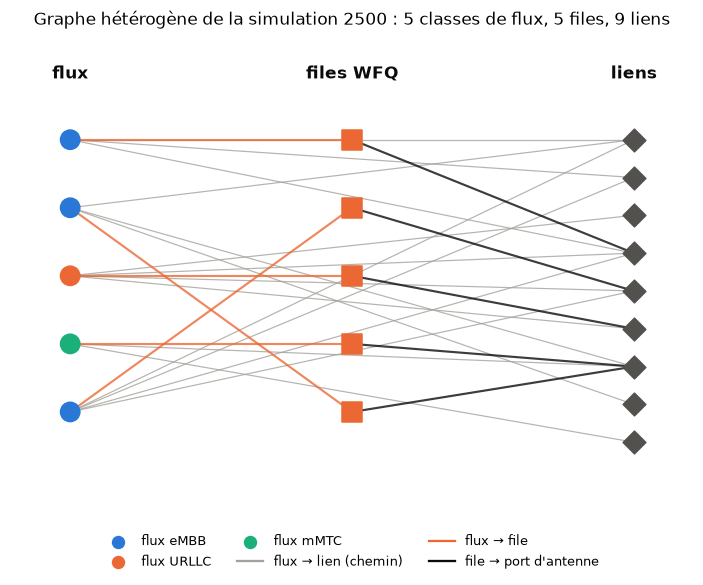

In [24]:
# Dessin d'un petit graphe (une simulation à peu de flux)
small = min(graphs, key=lambda s: abs(len(graphs[s]["xf"]) - 7) + abs(len(graphs[s]["xl"]) - 9) + abs(len(graphs[s]["xq"]) - 5))
g = graphs[small]
H = nx.DiGraph()
F = [f"f{i}" for i in range(len(g["xf"]))]; Qn = [f"q{i}" for i in range(len(g["xq"]))]; L = [f"l{i}" for i in range(len(g["xl"]))]
for i, p in enumerate(g["path"]):   # arêtes flux -> liens du chemin, et flux -> sa file
    for k, l in enumerate(p[p >= 0]): H.add_edge(F[i], L[l], kind="path")
    H.add_edge(F[i], Qn[g["fq"][i]], kind="queue")
for i, p in enumerate(g["path"]): H.add_edge(Qn[g["fq"][i]], L[p[0]], kind="port")   # file -> port de l'antenne
pos = {}
for col, nodes in enumerate((F, Qn, L)):
    for j, n in enumerate(nodes): pos[n] = (col * 2.0, -j * (len(F) / max(len(nodes), 1)))
fig, ax = plt.subplots(figsize=(8, 5.5))
slice_of = ["eMBB" if x[0] > 0 else ("URLLC" if x[1] > 0 else "mMTC") for x in g["xf"]]
for kind, col, w in (("path", BASE, .8), ("queue", "#eb6834", 1.4), ("port", INK, 1.4)):
    nx.draw_networkx_edges(H, pos, edgelist=[(u, v) for u, v, k in H.edges(data="kind") if k == kind], edge_color=col, width=w, arrows=False, ax=ax, alpha=.8)
nx.draw_networkx_nodes(H, pos, nodelist=F, node_color=[SLICE_COL[s] for s in slice_of], node_size=160, ax=ax)
nx.draw_networkx_nodes(H, pos, nodelist=Qn, node_color="#eb6834", node_shape="s", node_size=160, ax=ax)
nx.draw_networkx_nodes(H, pos, nodelist=L, node_color=MUTED, node_shape="D", node_size=110, ax=ax)
top = max(y for _, y in pos.values())
for x, t in ((0, "flux"), (2, "files WFQ"), (4, "liens")): ax.text(x, top + .9, t, ha="center", fontsize=11, color=INK, weight="bold")
for s, c in SLICE_COL.items(): ax.scatter([], [], color=c, s=60, label=f"flux {s}")
ax.plot([], [], color=BASE, label="flux → lien (chemin)"); ax.plot([], [], color="#eb6834", label="flux → file"); ax.plot([], [], color=INK, label="file → port d'antenne")
ax.legend(loc="lower center", bbox_to_anchor=(.5, -.18), ncol=3, fontsize=8.5)
ax.set_ylim(min(y for _, y in pos.values()) - .8, top + 1.6); ax.axis("off")
ax.set_title(f"Graphe hétérogène de la simulation {small} : {len(F)} classes de flux, {len(Qn)} files, {len(L)} liens", pad=4)
save(fig, "fig_graph")

### 5.2 Architecture

Modèle `SliceGNN` (`code/gnn.py`), inspiré de RouteNet. Les états cachés ont la dimension $d = 64$. Après encodage des attributs par trois MLP (un par type de nœud), on répète $T = 4$ fois :

1. **Flux ← liens et file (lecture du chemin).** Chaque flux parcourt son chemin avec un **GRU** initialisé par son état $h_f$. Au pas $k$, l'entrée est $[h_{\ell_k}, h_q \cdot \mathbb 1_{k=0}]$ : l'état du $k$-ième lien, plus l'état de sa file WFQ au premier saut (port de l'antenne). Le dernier état caché devient le nouveau $h_f$. Les sorties intermédiaires $o_{f,k}$ décrivent le flux *tel qu'il arrive* sur chaque lien. **L'ordre compte** : un flux qui perd des paquets en amont charge moins les liens en aval. Une agrégation par somme ou moyenne, comme dans un GCN, ignorerait cet ordre.
2. **Liens ← flux.** $m_\ell = \frac{\sum_{(f,k):\ell_k=\ell} w_f\, o_{f,k}}{\sum w_f}$ (moyenne pondérée par la multiplicité des classes), puis $h_\ell \leftarrow \mathrm{GRUCell}(m_\ell, h_\ell)$.
3. **Files ← flux.** Même agrégation sur les flux servis par la file, puis $h_q \leftarrow \mathrm{GRUCell}(m_q, h_q)$.

**Sortie** : un MLP $64 \to 64 \to 32 \to 2$ appliqué à $h_f$ donne [log10 délai, pertes] standardisés.

**Pourquoi ce choix plutôt que GCN, GraphSAGE ou GAT ?** (voir aussi Xu et al., 2019, sur le choix de l'agrégation) (i) Le graphe est **hétérogène** et biparti ; un GCN homogène suppose des voisins de même nature. (ii) L'information pertinente circule **le long de chemins ordonnés** : le GRU sur le chemin modélise cet ordre, pas l'agrégation par ensemble de GraphSAGE ou GAT. (iii) Les dépendances sont **circulaires** (flux ↔ liens) et longues : les itérations avec mémoire (GRU) approchent ce point fixe mieux que quelques couches empilées. (iv) Le **nombre de voisins varie fortement** (de 1 à plusieurs centaines de flux par lien) : une moyenne pondérée reste stable, alors qu'une somme exploserait.

**Contrôle du surapprentissage.** Validation sur des topologies jamais vues, arrêt précoce (patience de 6 époques) avec restauration des meilleurs poids, réduction du taux d'apprentissage sur plateau, décroissance de poids 1e-5, écrêtage du gradient à 1. Le modèle compte 107 k paramètres pour 183 323 classes de flux en entraînement.

In [25]:
# Hyperparamètres du GNN (voir code/run_gnn.py et code/gnn.py).
hp = pd.DataFrame([("dimension cachée d", 64), ("itérations T", 4), ("optimiseur", "Adam, lr 1e-3, weight decay 1e-5"),
    ("lot", "16 simulations"), ("époques max / patience", "40 / 6"), ("réduction du lr", "×0,5 après 2 époques sans gain"),
    ("perte", "MSE pondérée par w sur les 2 cibles standardisées"), ("paramètres", "107 426")], columns=["hyperparamètre", "valeur"])
hp

,hyperparamètre,valeur
0,dimension cachée d,64
1,itérations T,4
2,optimiseur,"Adam, lr 1e-3, weight decay 1e-5"
3,lot,16 simulations
4,époques max / patience,40 / 6
5,réduction du lr,"×0,5 après 2 époques sans gain"
6,perte,MSE pondérée par w sur les 2 cibles standardisées
7,paramètres,107 426


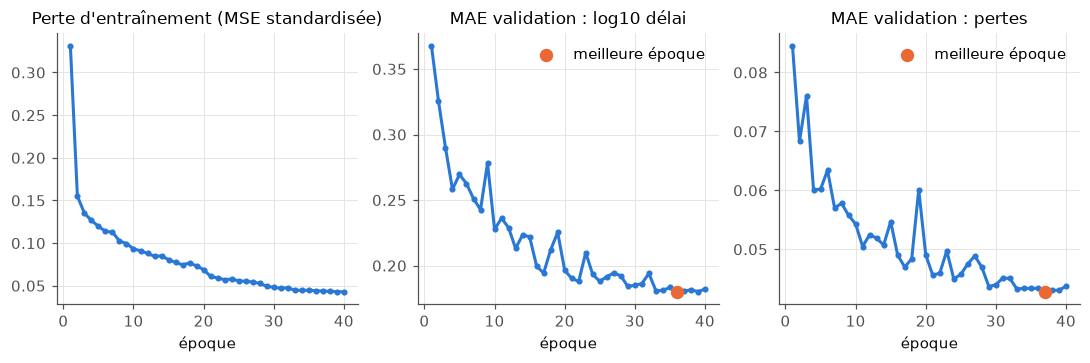

,epoch,train_mse,val_mae_delay,val_mae_loss,time
0,1,0.3316,0.3679,0.0846,25.7640
1,2,0.1551,0.3257,0.0683,27.3255
2,3,0.1351,0.2901,0.0760,29.3407
3,4,0.1265,0.2582,0.0601,29.1925
4,5,0.1197,0.2695,0.0602,29.8942
5,6,0.1136,0.2626,0.0634,27.8414
6,7,0.1129,0.2511,0.0570,29.5511
7,8,0.1025,0.2427,0.0578,29.6343
8,9,0.0994,0.2782,0.0558,28.4047
9,10,0.0934,0.2276,0.0543,29.9804


In [26]:
# Entraînement : lancé en script (≈ 20 s / époque sur GPU RTX 4070, ≈ 100 s / époque sur CPU 16 cœurs)
import torch
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
GNN_RUNS = {
    "gnn": [], "gnn_seed1": ["--seed", "1"], "gnn_seed2": ["--seed", "2"],
    "gnn_T0": ["--T", "0"], "gnn_noqueue": ["--no-queues"],
    "gnn_no_reservation": ["--drop", "reservation"], "gnn_no_charge": ["--drop", "charge"],
    "gnn_no_physique": ["--drop", "physique"], "gnn_no_allocation": ["--drop", "allocation"],
    "gnn_shift": ["--split", "shift"],
}
for name, extra in GNN_RUNS.items():
    if FORCE or not os.path.exists(os.path.join(RESULTS, f"{name}_preds.parquet")):
        subprocess.run([sys.executable, os.path.join("code", "run_gnn.py"), "--name", name, "--device", DEVICE] + extra, check=True)
hist = pd.read_csv(os.path.join(RESULTS, "gnn_history.csv"))
fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))
ax[0].plot(hist.epoch, hist.train_mse, color=ACCENT, lw=2, marker="o", ms=3); ax[0].set(title="Perte d'entraînement (MSE standardisée)", xlabel="époque")
ax[1].plot(hist.epoch, hist.val_mae_delay, color=ACCENT, lw=2, marker="o", ms=3); ax[1].set(title="MAE validation : log10 délai", xlabel="époque")
ax[2].plot(hist.epoch, hist.val_mae_loss, color=ACCENT, lw=2, marker="o", ms=3); ax[2].set(title="MAE validation : pertes", xlabel="époque")
for a, col in ((ax[1], "val_mae_delay"), (ax[2], "val_mae_loss")):
    b = hist[col].idxmin(); a.scatter(hist.epoch[b], hist[col][b], s=60, color="#eb6834", zorder=3, label="meilleure époque"); a.legend()
save(fig, "fig_training")
hist.round(4)

---
## 6. Comparaison (L6)

### 6.1 Évaluation globale et événementielle (test, topologies jamais vues)

In [27]:
# Livrable L6 : comparaison des 5 modèles sur le test, globalement et par sous-ensemble.
# evaluate() joint les prédictions aux métadonnées et calcule MAE / MSE pondérées par flux.
MAIN = ["naive", "ridge", "hgb", "mlp", "gnn"]
res = evaluate(MAIN, meta, labels=LAB)
res.to_csv(os.path.join(RESULTS, "comparaison_test.csv"), index=False)
piv = res.pivot(index="modèle", columns="sous_ensemble", values=["MAE_delay", "MSE_delay", "MAE_loss", "MSE_loss"])
piv = piv.reindex([LAB[m] for m in MAIN])
piv.loc[:, (slice(None), ["global", "hors événement", "événement", "surcharge", "délestage"])].round(4)

,MAE_delay,MSE_delay,MAE_loss,MSE_loss,MAE_delay,MSE_delay,MAE_loss,MSE_loss,MAE_delay,MSE_delay,MAE_loss,MSE_loss,MAE_delay,MSE_delay,MAE_loss,MSE_loss,MAE_delay,MSE_delay,MAE_loss,MSE_loss
sous_ensemble,global,global,global,global,hors événement,hors événement,hors événement,hors événement,événement,événement,événement,événement,surcharge,surcharge,surcharge,surcharge,délestage,délestage,délestage,délestage
modèle,,,,,,,,,,,,,,,,,,,,
Naïf,0.8255,1.2865,0.1965,0.0892,0.6862,0.7607,0.1528,0.0537,1.7065,4.6116,0.4724,0.3138,1.7225,5.0353,0.5489,0.3859,1.6440,2.9555,0.1731,0.0319
Ridge,0.5216,0.5327,0.1317,0.0387,0.4508,0.3725,0.1121,0.0284,0.9694,1.5456,0.2555,0.1037,1.0712,1.8126,0.2946,0.1260,0.5716,0.5018,0.1029,0.0165
Gradient Boosting,0.2765,0.3113,0.0669,0.0202,0.2151,0.1817,0.0532,0.0129,0.6644,1.1304,0.1538,0.0665,0.7487,1.3268,0.1859,0.0824,0.3350,0.3630,0.0283,0.0043
MLP,0.3430,0.3615,0.0816,0.0235,0.2857,0.2272,0.0671,0.0152,0.7051,1.2110,0.1733,0.0757,0.7974,1.4257,0.2072,0.0938,0.3444,0.3720,0.0408,0.0049
GNN,0.1746,0.1404,0.0445,0.0104,0.1594,0.1223,0.0392,0.0082,0.2707,0.2548,0.0781,0.0244,0.3116,0.3062,0.0955,0.0305,0.1111,0.0537,0.0104,0.0009


In [28]:
# Variabilité du GNN selon l'initialisation (3 graines), à comparer aux écarts entre modèles
seeds = pd.DataFrame([dict(graine=i, **{f"{k} {sub}": metrics(d)[k] for sub, d in
            (("global", dd), ("événement", dd[dd.event])) for k in ("MAE_delay", "MAE_loss")})
            for i, dd in ((i, load_preds(n, meta)) for i, n in enumerate(["gnn", "gnn_seed1", "gnn_seed2"]))])
seeds.loc["moyenne"] = seeds.mean(); seeds.loc["écart-type"] = seeds.iloc[:3].std()
seeds.round(4)

,graine,MAE_delay global,MAE_loss global,MAE_delay événement,MAE_loss événement
0,0.0,0.1746,0.0445,0.2707,0.0781
1,1.0,0.1671,0.0422,0.2651,0.0740
2,2.0,0.1715,0.0433,0.2650,0.0761
moyenne,1.0,0.1711,0.0433,0.2669,0.0761
écart-type,1.0,0.0038,0.0012,0.0033,0.0021


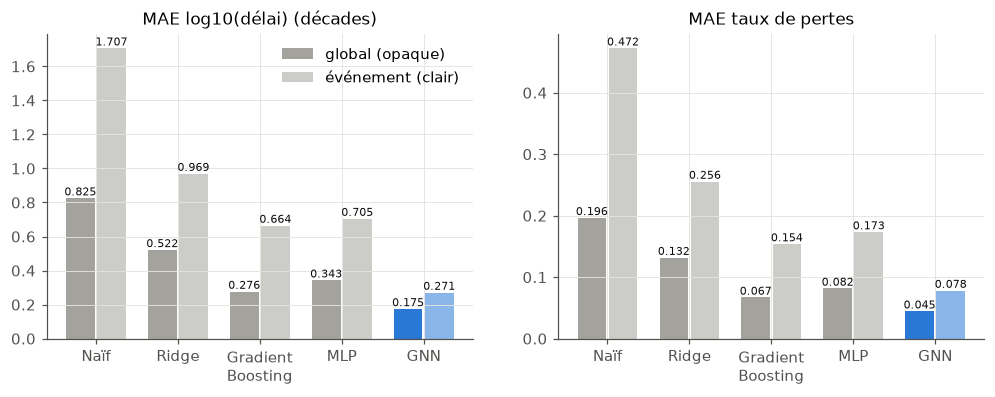

In [29]:
# Figure de comparaison : MAE globale (couleur pleine) et pendant les événements (claire).
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
subs = ["global", "événement"]
x = np.arange(len(MAIN)); wdt = .38
for a, met, ttl in ((ax[0], "MAE_delay", "MAE log10(délai) (décades)"), (ax[1], "MAE_loss", "MAE taux de pertes")):
    for j, s in enumerate(subs):
        v = [res[(res.modèle == LAB[m]) & (res.sous_ensemble == s)][met].iloc[0] for m in MAIN]
        bars = a.bar(x + (j - .5) * wdt, v, wdt * .92, color=[ACCENT if m == "gnn" else BASE for m in MAIN],
                     alpha=1 if s == "global" else .55, label=s)
        for xi, vi in zip(x + (j - .5) * wdt, v): a.text(xi, vi, f"{vi:.3f}", ha="center", va="bottom", fontsize=7.5, color=INK)
    a.set_xticks(x, [LAB[m].replace(" ", chr(10)) for m in MAIN]); a.set_title(ttl)
ax[0].legend(["global (opaque)", "événement (clair)"], loc="upper right")
save(fig, "fig_comparison")

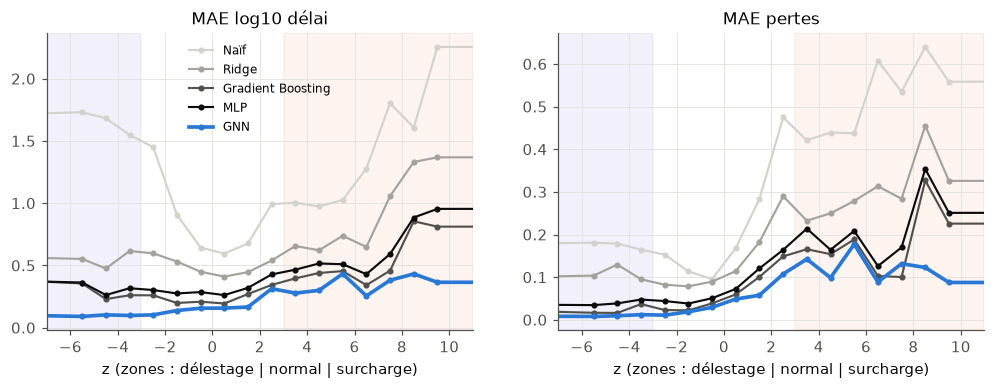

In [30]:
# Erreur en fonction de l'écart z au régime habituel
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
bins_z = np.r_[-30, np.arange(-6, 10.5, 1), 1e9]
for m in MAIN:
    d = load_preds(m, meta)
    d["ed"] = (d.p_delay - d.y_delay).abs(); d["el"] = (d.p_loss - d.y_loss).abs()   # erreurs absolues
    g = d.groupby(pd.cut(d.z.clip(-6.5, 10.5), bins_z), observed=True)
    mid = [i.mid for i in g.size().index]
    for a, col in ((ax[0], "ed"), (ax[1], "el")):
        v = g.apply(lambda x: np.average(x[col].fillna(0), weights=x.w * x[col].notna()), include_groups=False)
        a.plot(mid, v, lw=2.4 if m == "gnn" else 1.4, color=ACCENT if m == "gnn" else {"naive": "#d3d2cd", "ridge": BASE, "hgb": MUTED, "mlp": INK}[m],
               marker="o", ms=3, label=LAB[m])
for a, t in ((ax[0], "MAE log10 délai"), (ax[1], "MAE pertes")):
    a.axvspan(-7, -3, color=EVENT_COL["délestage"], alpha=.08); a.axvspan(3, 11, color=EVENT_COL["surcharge"], alpha=.08)
    a.set(xlabel="z (zones : délestage | normal | surcharge)", title=t, xlim=(-7, 11))
ax[0].legend(fontsize=8); save(fig, "fig_errors_z")

In [31]:
# Par type de slice (test, global)
rows = []
for m in MAIN:
    d = load_preds(m, meta)
    for s in ["eMBB", "URLLC", "mMTC"]:
        rows.append(dict(modèle=LAB[m], slice=s, **metrics(d[d.slice_type == s])))
per_slice = pd.DataFrame(rows).pivot(index="modèle", columns="slice", values=["MAE_delay", "MAE_loss"]).reindex([LAB[m] for m in MAIN])
per_slice.round(4)

MAE_delay                 MAE_loss                
slice                 URLLC    eMBB    mMTC    URLLC    eMBB    mMTC
modèle                                                              
Naïf                 0.7528  0.6541  0.8573   0.2167  0.2077  0.1898
Ridge                0.5060  0.5749  0.5230   0.1360  0.1493  0.1294
Gradient Boosting    0.2455  0.3395  0.2819   0.0584  0.0920  0.0680
MLP                  0.3046  0.3817  0.3521   0.0704  0.1055  0.0835
GNN                  0.1937  0.2568  0.1640   0.0466  0.0709  0.0423

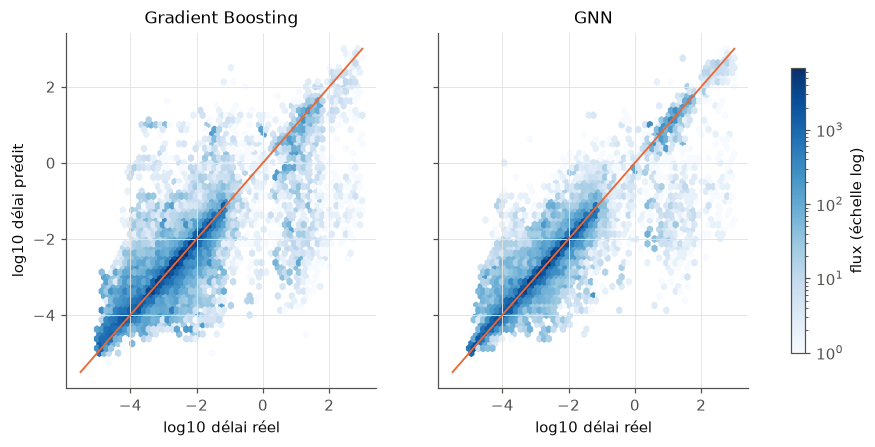

In [32]:
# Hexbin : densité des couples (réel, prédit) ; la diagonale orange = prédiction parfaite.
# Prédit vs réel (log10 délai), test
fig, ax = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)
for a, m in zip(ax, ["hgb", "gnn"]):
    d = load_preds(m, meta).dropna(subset=["y_delay"])
    hb = a.hexbin(d.y_delay, d.p_delay, C=d.w, reduce_C_function=np.sum, gridsize=60, bins="log", cmap="Blues", extent=(-5.5, 3, -5.5, 3))
    a.plot([-5.5, 3], [-5.5, 3], color="#eb6834", lw=1.2); a.set(xlabel="log10 délai réel", title=LAB[m])
ax[0].set_ylabel("log10 délai prédit"); fig.colorbar(hb, ax=ax, shrink=.8, label="flux (échelle log)")
save(fig, "fig_scatter")

### 6.2 Utilité opérationnelle : détecter les violations de SLA

Un opérateur ne regarde pas la MAE : il veut savoir **quelles slices vont violer leur SLA**. On transforme le délai prédit en décision « SLA délai violé ? » pour eMBB (10 ms) et URLLC (0,5 ms). Pour mMTC (10 s), il n'y a presque aucune violation.

In [33]:
# Utilité opérationnelle : on transforme le délai prédit en décision « SLA violé ? » et on
# la compare à la vraie violation. Exactitude équilibrée = moyenne des rappels des deux
# classes (insensible au déséquilibre) ; F1 de la classe « violation ».
from sklearn.metrics import balanced_accuracy_score, f1_score
rows = []
for m in MAIN:
    d = load_preds(m, meta).dropna(subset=["y_delay"])
    d = d[d.slice_type.isin(["eMBB", "URLLC"])]
    thr = np.log10(d.slice_type.map(SLA_DELAY))      # seuil SLA de chaque flux, en log10
    yt, yp = d.y_delay > thr, d.p_delay > thr         # violation réelle / violation prédite
    for sub, mask in (("global", np.ones(len(d), bool)), ("événement", d.event.to_numpy())):
        rows.append(dict(modèle=LAB[m], sous_ensemble=sub,
                         exactitude_équilibrée=balanced_accuracy_score(yt[mask], yp[mask], sample_weight=d.w[mask]),
                         F1_violation=f1_score(yt[mask], yp[mask], sample_weight=d.w[mask])))
sla_res = pd.DataFrame(rows).pivot(index="modèle", columns="sous_ensemble").reindex([LAB[m] for m in MAIN])
sla_res.round(3)

exactitude_équilibrée           F1_violation          
sous_ensemble                    global événement       global événement
modèle                                                                  
Naïf                              0.500     0.500        0.690     0.874
Ridge                             0.765     0.746        0.778     0.905
Gradient Boosting                 0.907     0.836        0.912     0.941
MLP                               0.871     0.830        0.874     0.936
GNN                               0.926     0.858        0.929     0.944

### 6.3 Ablation

Deux types d'ablation :
* **features** : on retire une famille et on ré-entraîne chaque modèle : (a) *réservation* (δ, poids WFQ, débit réservé, charges de file) ; (b) *charge* (charges offertes des files, du port et des liens, nombre de flux) ; (c) *physique* (délais de file pleine) ; (c') *allocation* = réservation + physique. Le délai de file pleine dépend du débit WFQ effectif, donc des poids : il faut retirer les deux familles pour supprimer toute information de réservation ;
* **structure du GNN** : (d) **T = 0**, une seule lecture du chemin sans rétroaction flux → liens, donc sans interactions entre flux ; (e) **sans nœuds « file »** : le GNN ne voit plus la séparation par slice au port de l'antenne.

In [34]:
# Ablation : ré-entraînement des modèles tabulaires sans chaque famille de features, puis
# tableau de toutes les variantes (y compris les ablations de structure du GNN).
for drop in ("reservation", "charge", "physique", "allocation"):
    run_tabular.run("topo", drop, ("ridge", "hgb", "mlp"), force=FORCE)
abl_rows = []
for m in ["ridge", "hgb", "mlp", "gnn"]:
    for var_, lab_ in ((m, "complet"), (f"{m}_no_reservation", "sans réservation"), (f"{m}_no_charge", "sans charge"),
                       (f"{m}_no_physique", "sans physique"), (f"{m}_no_allocation", "sans allocation")):
        r = metrics(load_preds(var_, meta)); abl_rows.append(dict(modèle=LAB[m], variante=lab_, **r))
for var_, lab_ in (("gnn_T0", "T = 0 (sans interactions)"), ("gnn_noqueue", "sans nœuds file")):
    abl_rows.append(dict(modèle="GNN", variante=lab_, **metrics(load_preds(var_, meta))))
abl = pd.DataFrame(abl_rows)
ref = abl[abl.variante == "complet"].set_index("modèle")   # MAE du modèle complet, pour les écarts
abl["Δ MAE délai"] = abl.MAE_delay - abl.modèle.map(ref.MAE_delay)
abl["Δ MAE pertes"] = abl.MAE_loss - abl.modèle.map(ref.MAE_loss)
abl.to_csv(os.path.join(RESULTS, "ablation.csv"), index=False)
abl[["modèle", "variante", "MAE_delay", "MAE_loss", "Δ MAE délai", "Δ MAE pertes"]].round(4)

,modèle,variante,MAE_delay,MAE_loss,Δ MAE délai,Δ MAE pertes
0,Ridge,complet,0.5216,0.1317,0.0000,0.0000
1,Ridge,sans réservation,0.5527,0.1398,0.0311,0.0081
2,Ridge,sans charge,0.5557,0.1763,0.0342,0.0446
3,Ridge,sans physique,0.6053,0.1331,0.0837,0.0014
4,Ridge,sans allocation,0.6049,0.1540,0.0833,0.0223
5,Gradient Boosting,complet,0.2765,0.0669,0.0000,0.0000
6,Gradient Boosting,sans réservation,0.3137,0.0766,0.0372,0.0097
7,Gradient Boosting,sans charge,0.4291,0.1520,0.1526,0.0851
8,Gradient Boosting,sans physique,0.2787,0.0684,0.0022,0.0015
9,Gradient Boosting,sans allocation,0.4527,0.1283,0.1762,0.0614


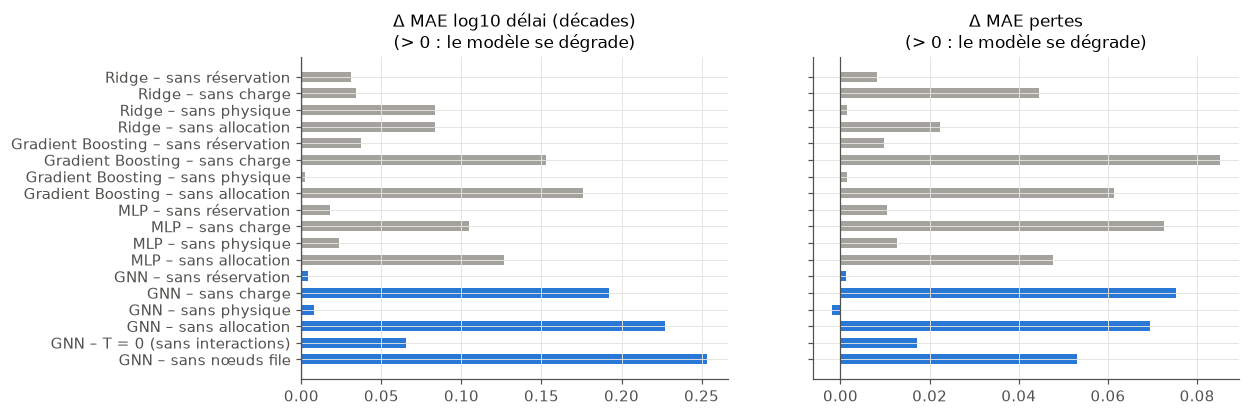

In [35]:
# Figure d'ablation : hausse de la MAE par rapport au modèle complet (> 0 = dégradation).
a2 = abl[abl.variante != "complet"].copy(); a2["lab"] = a2.modèle + " – " + a2.variante
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for a, col, ttl in ((ax[0], "Δ MAE délai", "Δ MAE log10 délai (décades)"), (ax[1], "Δ MAE pertes", "Δ MAE pertes")):
    a.barh(a2.lab, a2[col], color=[ACCENT if m == "GNN" else BASE for m in a2.modèle], height=.6)
    a.axvline(0, color=MUTED, lw=.8); a.set_title(ttl + "\n(> 0 : le modèle se dégrade)")
ax[0].invert_yaxis(); save(fig, "fig_ablation")

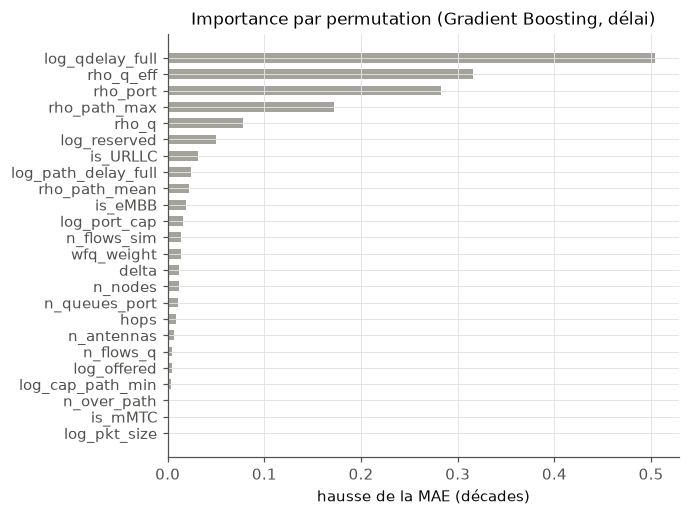

log_qdelay_full        0.5039
rho_q_eff              0.3159
rho_port               0.2824
rho_path_max           0.1717
rho_q                  0.0776
log_reserved           0.0501
is_URLLC               0.0314
log_path_delay_full    0.0238
dtype: float64

In [36]:
# Importance par permutation (Gradient Boosting, cible délai, échantillon du test)
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
p = json.load(open(os.path.join(RESULTS, "hgb_params.json")))["best"]["y_delay"]
trd = ft[ft.sim.isin(splits["topo"]["train"])].dropna(subset=["y_delay"])
ted = ft[ft.sim.isin(splits["topo"]["test"])].dropna(subset=["y_delay"])
ted = ted.sample(min(30_000, len(ted)), weights="w", random_state=0)  # classes tirées au prorata de leur nombre de flux
hgb = HistGradientBoostingRegressor(max_iter=400, l2_regularization=1.0, random_state=0, **p).fit(trd[FEATURES], trd.y_delay, sample_weight=trd.w)
# importance = hausse de la MAE quand on mélange au hasard une feature (Breiman, 2001)
pi = permutation_importance(hgb, ted[FEATURES], ted.y_delay, scoring="neg_mean_absolute_error", n_repeats=3, random_state=0, n_jobs=1)
imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(6, 5)); ax.barh(imp.index, imp.values, color=BASE, height=.6)
ax.set(title="Importance par permutation (Gradient Boosting, délai)", xlabel="hausse de la MAE (décades)"); save(fig, "fig_importance")
imp.sort_values(ascending=False).head(8).round(4)

### 6.4 Décalage de distribution : généralisation aux grands réseaux

Tous les modèles sont ré-entraînés sur le découpage `shift` : entraînement sur les petits et moyens réseaux, test sur les topologies les plus grandes.

In [37]:
# Décalage de distribution : modèles entraînés sur petits / moyens réseaux, testés sur les plus grands.
run_tabular.run("shift", None, ("naive", "ridge", "hgb", "mlp"), force=FORCE)
rows = []
for m in MAIN:
    r_topo = metrics(load_preds(m, meta)); r_shift = metrics(load_preds(f"{m}_shift", meta))
    rows.append(dict(modèle=LAB[m], MAE_délai_topo=r_topo["MAE_delay"], MAE_délai_shift=r_shift["MAE_delay"],
                     MAE_pertes_topo=r_topo["MAE_loss"], MAE_pertes_shift=r_shift["MAE_loss"]))
shift = pd.DataFrame(rows); shift.to_csv(os.path.join(RESULTS, "shift.csv"), index=False)
ev = evaluate([f"{m}_shift" for m in MAIN], meta, labels={f"{m}_shift": LAB[m] for m in MAIN})
shift = shift.merge(ev[ev.sous_ensemble == "événement"][["modèle", "MAE_delay"]].rename(columns={"MAE_delay": "MAE_délai_shift_événement"}), on="modèle")
shift.round(4)

,modèle,MAE_délai_topo,MAE_délai_shift,MAE_pertes_topo,MAE_pertes_shift,MAE_délai_shift_événement
0,Naïf,0.8255,0.8400,0.1965,0.2059,1.5563
1,Ridge,0.5216,0.5522,0.1317,0.1388,0.8373
2,Gradient Boosting,0.2765,0.2925,0.0669,0.0748,0.5732
3,MLP,0.3430,0.3612,0.0816,0.0910,0.6004
4,GNN,0.1746,0.2033,0.0445,0.0526,0.2834


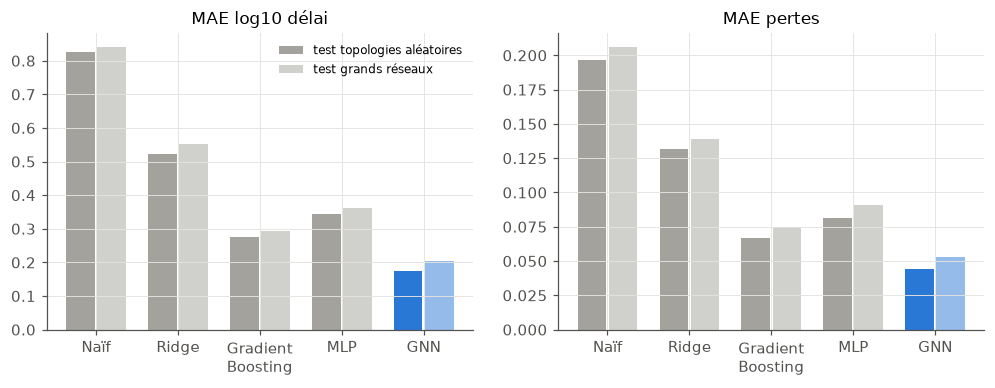

In [38]:
# Figure : MAE sur le test aléatoire contre MAE sur le test « grands réseaux ».
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
x = np.arange(len(MAIN)); wdt = .38
for a, (c1, c2), ttl in ((ax[0], ("MAE_délai_topo", "MAE_délai_shift"), "MAE log10 délai"), (ax[1], ("MAE_pertes_topo", "MAE_pertes_shift"), "MAE pertes")):
    a.bar(x - wdt / 2, shift[c1], wdt * .92, color=[ACCENT if m == "gnn" else BASE for m in MAIN], label="test topologies aléatoires")
    a.bar(x + wdt / 2, shift[c2], wdt * .92, color=[ACCENT if m == "gnn" else BASE for m in MAIN], alpha=.5, label="test grands réseaux")
    a.set_xticks(x, [m.replace(" ", chr(10)) for m in shift.modèle]); a.set_title(ttl)
ax[0].legend(fontsize=8); save(fig, "fig_shift")

---
## 7. Analyse (L6) — réponses aux questions du guide

**Quel modèle généralise le mieux ?** Le **GNN**, sur des topologies jamais vues :
* délai : MAE de 0,175 décade (erreur multiplicative typique d'environ ×1,5), contre 0,277 pour le Gradient Boosting, 0,343 pour le MLP, 0,522 pour Ridge et 0,826 pour le modèle naïf ;
* pertes : MAE de 0,045, contre 0,067 pour le Gradient Boosting ;
* la MSE suit le même classement : 0,140 contre 0,311 sur le délai. Le GNN fait donc moins de très grosses erreurs.

L'écart avec le Gradient Boosting (−37 % de MAE) est environ 25 fois plus grand que la variabilité du GNN entre trois initialisations (MAE de 0,167 à 0,175, écart-type de 0,004 décade) : le gain n'est pas un effet de hasard.

**Quel modèle résiste le mieux aux événements ?** Encore le **GNN**, et c'est là que l'écart est le plus net.
* Pendant les événements, sa MAE de délai passe à 0,271 (×1,55). Celle du Gradient Boosting passe à 0,664 (×2,4) et celle du MLP à 0,705 (×2,1).
* En **surcharge**, la configuration la plus risquée pour un opérateur, le GNN se trompe de 0,31 décade, contre 0,75 pour le Gradient Boosting.
* En **délestage**, l'erreur tombe à 0,11 contre 0,34.
* La figure d'erreur selon z montre que l'erreur de tous les modèles croît avec z, mais beaucoup moins pour le GNN. En délestage (z ≤ −3), l'erreur du GNN reste au niveau du régime normal (≈ 0,1 décade), alors que celle des modèles tabulaires remonte.

**Le GNN apporte-t-il un gain réel ?** Oui, et l'ablation montre d'où il vient.
* **Sans rétroaction flux → liens** (T = 0 : chaque flux lit une seule fois les états initiaux de son chemin), la MAE remonte à 0,240 (0,502 pendant les événements). Plus de la moitié du gain sur le Gradient Boosting vient donc des **interactions entre flux**, c'est-à-dire de la propagation des pertes et des congestions le long des chemins. Les features tabulaires ne peuvent pas la calculer.
* **Sans nœuds « file WFQ »**, la MAE monte à 0,428 : sans représentation explicite de la réservation par slice au port de l'antenne, le GNN est moins bon que le Gradient Boosting.
* En SLA, le gain est réel mais plus modeste : exactitude équilibrée de 0,926 contre 0,907 pour la décision « SLA de délai violé ? » (0,858 contre 0,836 pendant les événements). Une décision binaire loin du seuil est facile pour tous les modèles ; le GNN se distingue surtout près du seuil et sur l'ampleur des dégradations.

**Quelles features sont importantes ?**
* **Allocation** (δ, poids WFQ, réservation, délai de file pleine) : la retirer double l'erreur du GNN (0,175 → 0,402 ; 0,94 pendant les événements) et fait passer le Gradient Boosting de 0,277 à 0,453. C'est l'information de gestion des slices, et elle est indispensable.
* **Charge** (charges offertes des files, du port et des liens) : 0,175 → 0,367 pour le GNN.
* Les familles *réservation* et *physique* sont **redondantes** : chacune contient le poids WFQ (directement, ou à travers le débit effectif). Retirer l'une seulement ne coûte presque rien.
* La feature physique aide beaucoup les modèles simples : sans elle, Ridge passe de 0,522 à 0,605. Elle n'aide presque pas le GNN (0,182), qui **reconstruit lui-même** cette connaissance du domaine.
* Pour le Gradient Boosting, l'importance par permutation place en tête le délai de file pleine, la charge effective de la file et la charge du port.

**Les performances changent-elles quand la distribution du test diffère ?** Oui, modérément.
* Testés sur les plus grands réseaux (topologies ≥ 212 nœuds, absentes de l'entraînement), tous les modèles se dégradent : GNN 0,175 → 0,203, Gradient Boosting 0,277 → 0,293.
* Le GNN se dégrade un peu plus en relatif (+16 % contre +6 %), mais reste nettement le meilleur, y compris pendant les événements (0,283 contre 0,573).
* Son architecture n'a pas de taille fixe : il s'applique tel quel à des graphes plus grands, sans être ré-entraîné.

**Limites.**
1. **Un seul simulateur**, des régimes stationnaires, un transport filaire sans RAN radio. Les conclusions valent pour ce cadre.
2. **Les événements sont reconstruits** : ce sont des écarts au régime habituel, pas des transitions observées dans le temps. Le dataset n'a pas d'axe temporel.
3. **Le dataset a des défauts** (chemins incohérents, réservations hors chemin, sous-dimensionnement), corrigés ou documentés ; une partie des « surcharges » vient de ces réservations hors chemin.
4. **Une seule découpe aléatoire des topologies.** La variabilité n'est estimée que sur l'initialisation du GNN (3 graines), pas sur la découpe.
5. **Le GNN n'a pas totalement convergé** en 40 époques ; il coûte environ 16 min sur GPU, contre 2 min pour le Gradient Boosting.
6. **Le modèle prédit la QoS, il n'optimise pas encore δ.** Le boucler avec un optimiseur est l'étape suivante.

**Dans quelles conditions une approche GNN apporte-t-elle une valeur ajoutée pour la gestion dynamique des slices B5G ?** D'après nos expériences :
1. quand la QoS d'une slice dépend de **ressources partagées et d'effets en cascade** (pertes en amont, congestion de liens communs) que des features par flux ne résument pas. Le gain vient de la rétroaction flux ↔ liens (ablation T = 0) ;
2. quand le graphe **représente explicitement le levier de gestion**, ici les files WFQ par slice. Sans ces nœuds, le GNN perd tout son avantage ;
3. quand le réseau **sort de son régime habituel** (surcharges, délestages). C'est là que les modèles tabulaires échouent le plus et que le GNN garde une erreur stable : exactement le cas d'usage de la gestion *dynamique* ;
4. quand la topologie change ou grandit : le même modèle s'applique à des réseaux inédits.

À l'inverse, pour une décision grossière loin des seuils (SLA largement respecté ou largement violé), ou quand le coût d'entraînement compte, un Gradient Boosting bien alimenté en features physiques reste une solution solide et bien moins chère.

---
### Références citées dans ce notebook

* Breiman, L. (2001). Random Forests. *Machine Learning*, 45 (importance par permutation).
* Farreras, M., Paillissé, J., Fàbrega, L., Vilà, P. (2024). Generation of a network slicing dataset: The foundations for AI-based B5G resource management. *Data in Brief*, 55.
* Ferriol-Galmés, M. et al. (2023). RouteNet-Fermi: Network Modeling with Graph Neural Networks. *IEEE/ACM Transactions on Networking*.
* Friedman, J. H. (2001). Greedy function approximation: A gradient boosting machine. *Annals of Statistics*, 29(5).
* Hampel, F. R. (1974). The Influence Curve and its Role in Robust Estimation. *JASA*, 69(346).
* Kaufman, S., Rosset, S., Perlich, C., Stitelman, O. (2012). Leakage in data mining. *ACM TKDD*, 6(4).
* Leys, C. et al. (2013). Detecting outliers: use absolute deviation around the median. *J. Experimental Social Psychology*, 49(4).
* Parekh, A. K., Gallager, R. G. (1993). A generalized processor sharing approach to flow control. *IEEE/ACM ToN*, 1(3).
* Prechelt, L. (1998). Early Stopping – But When? *Neural Networks: Tricks of the Trade*.
* Roberts, D. R. et al. (2017). Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure. *Ecography*, 40(8).
* Rusek, K. et al. (2020). RouteNet: Leveraging Graph Neural Networks for network modeling and optimization in SDN. *IEEE JSAC*, 38(10).
* Tofallis, C. (2015). A better measure of relative prediction accuracy. *J. Operational Research Society*, 66(8).
* Xu, K., Hu, W., Leskovec, J., Jegelka, S. (2019). How Powerful are Graph Neural Networks? *ICLR*.

---
### Export des tableaux pour le rapport LaTeX

In [39]:
# Export des tableaux LaTeX (results/tables/), du résumé et des données de la présentation.
TAB = os.path.join(RESULTS, "tables"); os.makedirs(TAB, exist_ok=True)
def fnum(v, nd=3):
    return f"{v:.{nd}f}".replace(".", "{,}") if isinstance(v, (float, np.floating)) else str(v)
def to_tex(df, name, nd=3, best=None, col_fmt=None):
    # tableau booktabs ; best = {colonne: "min"|"max"} met la meilleure valeur en gras
    cols = list(df.columns)
    lines = [r"\begin{tabular}{" + (col_fmt or "l" + "r" * (len(cols) - 1)) + "}", r"\toprule",
             " & ".join(cols) + r" \\", r"\midrule"]
    bvals = {c: (df[c].min() if how == "min" else df[c].max()) for c, how in (best or {}).items()}
    for _, r in df.iterrows():
        cells = []
        for c in cols:
            s = fnum(r[c], nd).replace("%", r"\%").replace("_", r"\_")
            if c in bvals and isinstance(r[c], (float, np.floating)) and np.isclose(r[c], bvals[c]): s = r"\textbf{" + s + "}"
            cells.append(s)
        lines.append(" & ".join(cells) + r" \\")
    lines += [r"\bottomrule", r"\end{tabular}"]
    open(os.path.join(TAB, name + ".tex"), "w", encoding="utf-8").write("\n".join(lines))

for tgt, lab in (("delay", "delai"), ("loss", "pertes")):
    t = pd.DataFrame({"Modèle": [LAB[m] for m in MAIN]})
    for sub, short in (("global", "global"), ("hors événement", "hors év."), ("événement", "év."), ("surcharge", "surch."), ("délestage", "délest.")):
        t[f"MAE {short}"] = [res[(res.modèle == LAB[m]) & (res.sous_ensemble == sub)][f"MAE_{tgt}"].iloc[0] for m in MAIN]
    for sub, short in (("global", "global"), ("événement", "év.")):
        t[f"MSE {short}"] = [res[(res.modèle == LAB[m]) & (res.sous_ensemble == sub)][f"MSE_{tgt}"].iloc[0] for m in MAIN]
    to_tex(t, f"tab_{lab}", best={c: "min" for c in t.columns[1:]})

ps = per_slice.copy(); ps.columns = [f"MAE {'délai' if a == 'MAE_delay' else 'pertes'} {b}" for a, b in ps.columns]
to_tex(ps.reset_index().rename(columns={"modèle": "Modèle"}), "tab_slice", best={c: "min" for c in ps.columns})
sl = sla_res.copy(); sl.columns = [f"{'Exact. équil.' if a.startswith('exact') else 'F1 violation'} {b}" for a, b in sl.columns]
to_tex(sl.reset_index().rename(columns={"modèle": "Modèle"}), "tab_sla", best={c: "max" for c in sl.columns})
ab = abl[["modèle", "variante", "MAE_delay", "Δ MAE délai", "MAE_loss", "Δ MAE pertes"]].rename(columns={
    "modèle": "Modèle", "variante": "Variante", "MAE_delay": "MAE délai", "MAE_loss": "MAE pertes"})
to_tex(ab, "tab_ablation", col_fmt="llrrrr")
sh = shift.rename(columns={"modèle": "Modèle", "MAE_délai_topo": "MAE délai (topo)", "MAE_délai_shift": "MAE délai (grands)",
                           "MAE_pertes_topo": "MAE pertes (topo)", "MAE_pertes_shift": "MAE pertes (grands)",
                           "MAE_délai_shift_événement": "MAE délai (grands, év.)"})
to_tex(sh, "tab_shift", best={c: "min" for c in sh.columns[1:]})
to_tex(describe(splits, samples).rename(columns={"split": "Découpage", "part": "Partie", "simulations": "Simulations",
       "topologies": "Topologies", "noeuds_median": "Nœuds (médiane)"}), "tab_splits", nd=0, col_fmt="llrrr")
to_tex(tab.reset_index().rename(columns={"event_type": "Type", "flux": "Flux", "b_median": "$b$ médian", "part_b_sup_1": "part $b>1$",
       "delai_log_median": "log10 délai méd.", "pertes_median": "pertes méd.", "part": "Part"}), "tab_events", col_fmt="lrrrrrr")
summary = {"n_sims": int(len(samples)), "n_flows": int(ft.w.sum()), "n_classes": int(len(ft)), "n_topologies": int(samples.topology.nunique()),
           "events_share": float(np.average(ft.event, weights=ft.w)), "best_epoch": int(hist.val_mae_delay.idxmin() + 1)}
json.dump(summary, open(os.path.join(RESULTS, "summary.json"), "w"), indent=1)

# données de la présentation (lues par presentation/build_deck.js)
deck = {"summary": summary,
        "comparison": res.round(4).to_dict("records"),
        "ablation": abl.round(4).to_dict("records"),
        "shift": shift.round(4).to_dict("records"),
        "sla": sla_res.round(3).reset_index().pipe(lambda x: x.set_axis(["modèle"] + [f"{a} {b}" for a, b in x.columns[1:]], axis=1)).to_dict("records"),
        "seeds": seeds.round(4).reset_index().to_dict("records"),
        "events": tab.round(3).reset_index().to_dict("records"),
        "importance": imp.sort_values(ascending=False).head(8).round(4).to_dict()}
json.dump(deck, open(os.path.join(RESULTS, "deck_data.json"), "w", encoding="utf-8"), indent=1, ensure_ascii=False, default=float)
sorted(os.listdir(TAB))

['tab_ablation.tex',
 'tab_delai.tex',
 'tab_events.tex',
 'tab_pertes.tex',
 'tab_shift.tex',
 'tab_sla.tex',
 'tab_slice.tex',
 'tab_splits.tex']